From the [Muon Tutorials for Single-cell RNA-seq and ATAC-seq integration](https://muon-tutorials.readthedocs.io/en/latest/single-cell-rna-atac/pbmc10k/1-Gene-Expression-Processing.html)

In [6]:
# Single-cell packages

import matplotlib.pyplot as plt
import muon as mu
import numpy as np
import anndata as ad
import pysam

from pathlib import Path

# General helpful packages for data analysis and visualization
import pandas as pd
import scanpy as sc
import seaborn as sns
from muon import atac as ac  # the module containing function for scATAC data processing

import os, sys
os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]
import pybedtools
# Setting figure parameters
sc.settings.verbosity = 0

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
PROJECT_DATA_DIR = Path("/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")

ORGANISM_CODE = "hg38"
DATASET_NAME = "GSE249497_embryonic_orofacial_10x_raw"

# Libraries this notebook covers. Run it once per library: set SAMPLE_NAME, run all cells, then fill in
# celltype_map under "Cell Type Mapping" for that library before saving.
# GEO has no embryo IDs. The 3 CS12 libraries look like one pool and the CS13 libraries may be one embryo, so do not count them as independent replicates.
SAMPLES = [
    "CS12_01",
    "CS12_02",
    "CS12_03",
    "CS13_01",
    "CS13_02",
    "CS13_03",
    "CS13_04",
    "CS13_05",
    "CS14_01",
    "CS14_02",
    "CS14_03",
    "CS16_01",
    "CS16_02",
    "CS17_01",
    "CS17_02",
    "CS20_01",
    "CS20_02",
]
SAMPLE_NAME = "CS13_01"

RAW_DATA_DIR = PROJECT_DATA_DIR / "RAW_DATA" / "HUMAN"
PEAK_DATA_DIR = RAW_DATA_DIR / "peaks_macs3" / DATASET_NAME
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed" / ORGANISM_CODE / DATASET_NAME.replace("_10x_raw", "")

# Look up this library in the human raw-data metadata table (one row per library)
full_metadata_df = pd.read_csv(RAW_DATA_DIR / "metadata_summary.tsv", sep="\t", header=0)

sample_metadata_df = full_metadata_df[
    (full_metadata_df["dataset"] == DATASET_NAME) &
    (full_metadata_df["library"] == SAMPLE_NAME)
    ]

assert len(sample_metadata_df) == 1, f"Expected 1 metadata row for {DATASET_NAME} / {SAMPLE_NAME}, found {len(sample_metadata_df)}"
assert sample_metadata_df["status"].iloc[0] == "ready", f"Sample is not ready: {sample_metadata_df['status'].iloc[0]}"
assert pd.notna(sample_metadata_df["raw_h5mu"].iloc[0]), f"No raw h5mu listed for this sample: {sample_metadata_df['status_note'].iloc[0]}"

information_cols = ["dataset", "library", "tissue", "age", "condition", "sex_reported", "status_note"]
for col in information_cols:
    print(f"{col}: {sample_metadata_df[col].iloc[0]}")

TISSUE = sample_metadata_df["tissue"].iloc[0]
sample_h5mu_path = sample_metadata_df["raw_h5mu"].iloc[0]
sample_raw_data_dir = sample_metadata_df["raw_folder"].iloc[0]

# Raw RNA counts + fragment counts in this library's MACS3 peaks, built by
# RAW_DATA/HUMAN/scripts/24_build_library_h5mu.py. When set, it is read instead of the inputs below.
input_h5mu = RAW_DATA_DIR / sample_h5mu_path

# ENCODE raw_folder is the library folder. 10x datasets give only the dataset folder, with one subfolder per library.
SAMPLE_DATA_DIR = RAW_DATA_DIR / sample_raw_data_dir
if SAMPLE_DATA_DIR.name != SAMPLE_NAME:
    SAMPLE_DATA_DIR = SAMPLE_DATA_DIR / SAMPLE_NAME

# Fragment file of this library (its barcodes are the cell names in input_h5mu), for nucleosome signal filtering.
# ENCODE: fragments_atac_barcodes.tsv.gz; most 10x datasets: fragments.tsv.gz; Kanemaru: <library>_atac_fragments.tsv.gz
frag_candidates = [
    SAMPLE_DATA_DIR / "fragments_atac_barcodes.tsv.gz",
    SAMPLE_DATA_DIR / "fragments.tsv.gz",
    SAMPLE_DATA_DIR / f"{SAMPLE_NAME}_atac_fragments.tsv.gz",
]
frag_path = next((p for p in frag_candidates if p.exists()), frag_candidates[0])

assert frag_path.exists(), f"Fragment file not found: {frag_path}"
print(f"Fragment file found: {frag_path}")

assert input_h5mu.exists(), f"Input h5mu file not found: {input_h5mu}"
print(f"Input h5mu file found: {input_h5mu}")

# Set to None if you have 10X files instead of count files
rna_count_file = None
atac_count_file = None

# Set to None if you have matrix, features, barcode files instead of an h5 file
raw_h5_file = None

# If you want to keep all TFs to maximize overlap with the ground truth files, pass in a ground truth file path here.
tf_list_file = None

def default_tss_bed(species):
    """Prefer <species>_gene_tss.bed -- that is what the existing samples were built with."""
    annotation_dir = PROJECT_DIR / "data" / "genome_data" / "genome_annotation" / species
    preferred = annotation_dir / f"{species}_gene_tss.bed"
    return preferred if preferred.exists() else annotation_dir / "gene_tss.bed"

tss_path = default_tss_bed(ORGANISM_CODE)

SAMPLE_PROCESSED_DATA_DIR = PROCESSED_DATA_DIR / SAMPLE_NAME

if not SAMPLE_PROCESSED_DATA_DIR.exists():
    SAMPLE_PROCESSED_DATA_DIR.mkdir(parents=True)

print(f"Loading data for sample {SAMPLE_NAME}: {input_h5mu}")
# List the raw files of this library (read-only)
for file in sorted(SAMPLE_DATA_DIR.glob("*")):
    print(f"  - {file.name}")


dataset: GSE249497_embryonic_orofacial_10x_raw
library: CS13_01
tissue: human embryonic orofacial region
age: Carnegie stage 13
condition: embryo IDs not deposited
sex_reported: nan
status_note: MACS3 peaks and raw .h5mu built
Fragment file found: /gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/GSE249497_embryonic_orofacial_10x_raw/CS13_01/fragments.tsv.gz
Input h5mu file found: /gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/peaks_macs3/GSE249497_embryonic_orofacial_10x_raw/CS13_01/CS13_01_raw.h5mu
Loading data for sample CS13_01: /gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/peaks_macs3/GSE249497_embryonic_orofacial_10x_raw/CS13_01/CS13_01_raw.h5mu
  - filtered_feature_bc_matrix.h5
  - fragments.tsv.gz
  - fragments.tsv.gz.tbi


## Load in the Raw Data

In [54]:
def normalize_peak_format(peak_id: str) -> str:
    """
    Normalize peak format from chrN-start-end or chrN:start:end to chrN:start-end.
    Handles both formats as input and always outputs chrN:start-end.
    """
    if not isinstance(peak_id, str):
        return peak_id
    
    # Try to parse chr-start-end format (with dashes)
    parts = peak_id.split('-')
    if len(parts) >= 3:
        # Assume format is chr-start-end where chr might have dashes
        # Work backwards: the last two parts are start and end
        try:
            end = int(parts[-1])
            start = int(parts[-2])
            chrom = '-'.join(parts[:-2])  # Everything before the last two parts
            return f"{chrom}:{start}-{end}"
        except (ValueError, IndexError):
            pass
    
    # Already in chr:start-end format or some other format, return as-is
    return peak_id

def construct_from_gene_by_cell_matrices(rna_count_file, atac_count_file):
    assert rna_count_file.exists(), "rna count file does not exist"
    assert atac_count_file.exists(), "atac count file does not exist"
    
    rna_count_matrix = pd.read_csv(rna_count_file, header=0, index_col=0)
    atac_count_matrix = pd.read_csv(atac_count_file, header=0, index_col=0)
    
    rna_matrix = rna_count_matrix.T.values
    rna_metadata_df = pd.DataFrame(index=rna_count_matrix.columns)
    rna_features_df = pd.DataFrame(index=rna_count_matrix.index)
    
    atac_count_matrix.index = atac_count_matrix.index.map(normalize_peak_format)

    atac_matrix = atac_count_matrix.T.values
    atac_metadata_df = pd.DataFrame(index=atac_count_matrix.columns)
    atac_features_df = pd.DataFrame(index=atac_count_matrix.index)
    
    adata_rna = ad.AnnData(X=rna_matrix, obs=rna_metadata_df, var=rna_features_df)
    adata_rna.var["feature_types"] = "Gene Expression"
    adata_rna.var["gene_ids"] = adata_rna.var_names

    adata_atac = ad.AnnData(X=atac_matrix, obs=atac_metadata_df, var=atac_features_df)
    adata_atac.var["feature_types"] = "Peaks"
    adata_atac.var["gene_ids"] = adata_atac.var_names

    mdata = mu.MuData({'rna': adata_rna, 'atac': adata_atac})

    return mdata

def filter_to_human(mdata):
    """
    Filter a barnyard MuData object to hg38 ATAC peaks only,
    then strip the 'hg38.' prefix from peak IDs.
    """
    if "hg38" in mdata["atac"].var_names[0]:
        # annotate species from interval
        mdata["atac"].var["species"] = (
            mdata["atac"].var["interval"].str.split(".", n=1).str[0]
        )

        # keep only hg38 peaks
        hg38_mask = mdata["atac"].var["species"] == "hg38"
        mdata.mod["atac"] = mdata["atac"][:, hg38_mask].copy()

        # strip prefix from identifiers
        mdata.mod["atac"].var_names = (
            mdata.mod["atac"].var_names.str.replace(r"^hg38\.", "", regex=True)
        )
        mdata.mod["atac"].var["gene_ids"] = (
            mdata.mod["atac"].var["gene_ids"].str.replace(r"^hg38\.", "", regex=True)
        )
        mdata.mod["atac"].var["interval"] = (
            mdata.mod["atac"].var["interval"].str.replace(r"^hg38\.", "", regex=True)
        )
        mdata = mu.MuData(mdata.mod)

    return mdata

from scipy.stats import median_abs_deviation

def is_outlier(adata, metric: str, nmads: int):
    M = adata.obs[metric]
    outlier = (M < np.median(M) - nmads * median_abs_deviation(M)) | (
        np.median(M) + nmads * median_abs_deviation(M) < M
    )
    return outlier

Build the mdata object from the library's raw MuData (`input_h5mu`: raw RNA counts and fragment counts in its MACS3 peaks), or else from raw 10X genomic data, a 10x h5 file, or a counts file. If you build from counts files, you won't be able to run the ATAC-seq QC filtering steps that require fragment files.

In [55]:
if input_h5mu is not None:
    mdata = mu.read_h5mu(input_h5mu)
    print(f"Read {input_h5mu}")
elif rna_count_file is not None and atac_count_file is not None:
    rna_count_filepath = SAMPLE_DATA_DIR / rna_count_file
    atac_count_filepath = SAMPLE_DATA_DIR / atac_count_file
    
    mdata = construct_from_gene_by_cell_matrices(rna_count_filepath, atac_count_filepath)
    print("Constructed MuData object from count files.")
elif raw_h5_file is not None:
    mdata = mu.read_10x_h5(raw_h5_file)
else:
    mdata = mu.read_10x_mtx(SAMPLE_DATA_DIR)
        
mdata.var_names_make_unique()
display(mdata)

mdata.write(SAMPLE_PROCESSED_DATA_DIR / f"{SAMPLE_NAME}.h5mu")

/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1403: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1275: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


Read /gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/peaks_macs3/GSE249497_embryonic_orofacial_10x_raw/CS13_01/CS13_01_raw.h5mu


MuData object with n_obs × n_vars = 4396 × 204762
  obs:	'dataset', 'library'
  uns:	'source'
  2 modalities
    rna:	4396 x 36601
      var:	'gene_ids', 'feature_types', 'genome', 'interval'
    atac:	4396 x 168161
      var:	'chrom', 'start', 'end'

/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1403: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1275: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


# RNA

In [56]:
rna = mdata.mod['rna']
rna

AnnData object with n_obs × n_vars = 4396 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'interval'

## Preprocessing

### QC

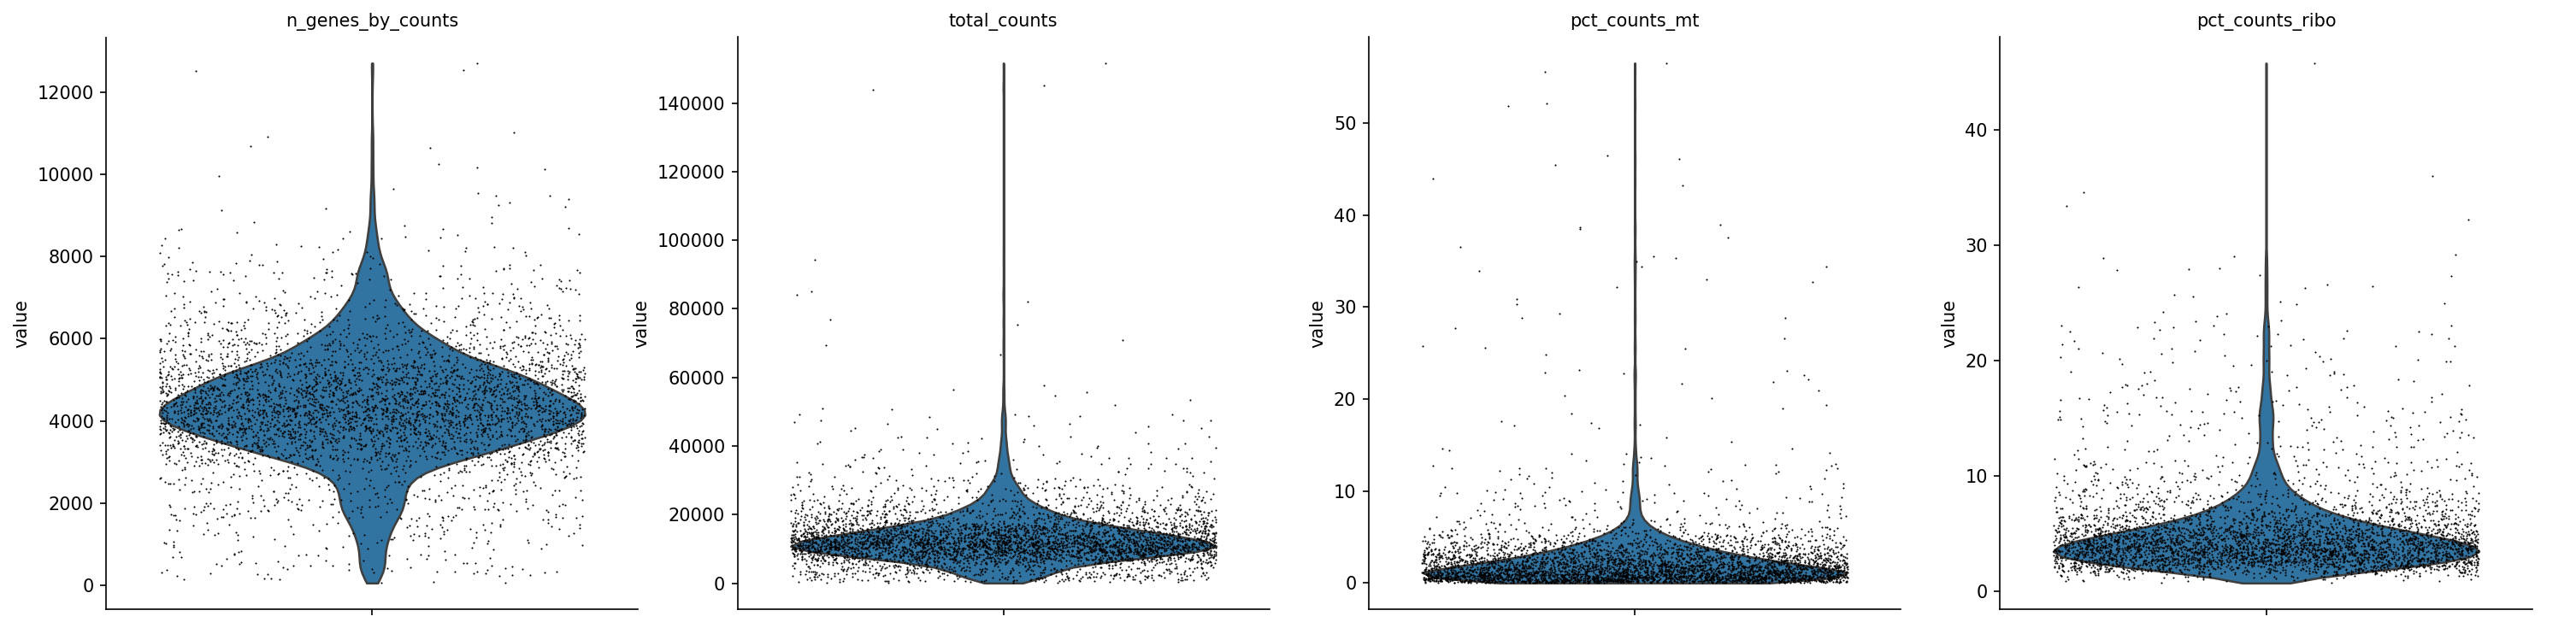

In [57]:
rna.var['mt'] = rna.var_names.str.upper().str.startswith('MT-')  # annotate the group of mitochondrial genes as 'mt'
rna.var['ribo'] = rna.var_names.str.upper().str.startswith('RPL') | rna.var_names.str.upper().str.startswith('RPS')  # annotate the group of ribosomal genes as 'ribo'
sc.pp.calculate_qc_metrics(rna, qc_vars=['mt', 'ribo'], percent_top=[20], log1p=True, inplace=True)

sc.pl.violin(rna, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo'],
             jitter=0.4, multi_panel=True)

Filter genes and cells based on the thresholds above

In [58]:
rna_filtered = rna.copy()

In [59]:
# Thresholds copied from the vena cava notebook; set them for this library from the violin plots above.
print(f"Cells before filtering: {rna.n_obs}")
mu.pp.filter_obs(rna_filtered, 'total_counts', lambda x: (x <= 40000) & (x >= 500))
mu.pp.filter_obs(rna_filtered, 'n_genes_by_counts', lambda x: (x >= 1500) & (x <= 8000))
mu.pp.filter_obs(rna_filtered, 'pct_counts_mt', lambda x: (x <= 10))
mu.pp.filter_obs(rna_filtered, 'pct_counts_ribo', lambda x: (x <= 15))

sc.pp.filter_genes(rna_filtered, min_cells=10)
print(f"Cells after filtering: {rna_filtered.n_obs}")

Cells before filtering: 4396
Cells after filtering: 4078


Detect and remove doublets

In [61]:
sc.pp.scrublet(rna_filtered)

# Filter out doublets
rna_filtered = rna_filtered[~rna_filtered.obs["predicted_doublet"], :]
print(f"Number of genes after cell filter: {rna_filtered.n_vars}")

Number of genes after cell filter: 24347


Check to see how the data looks after filtering.

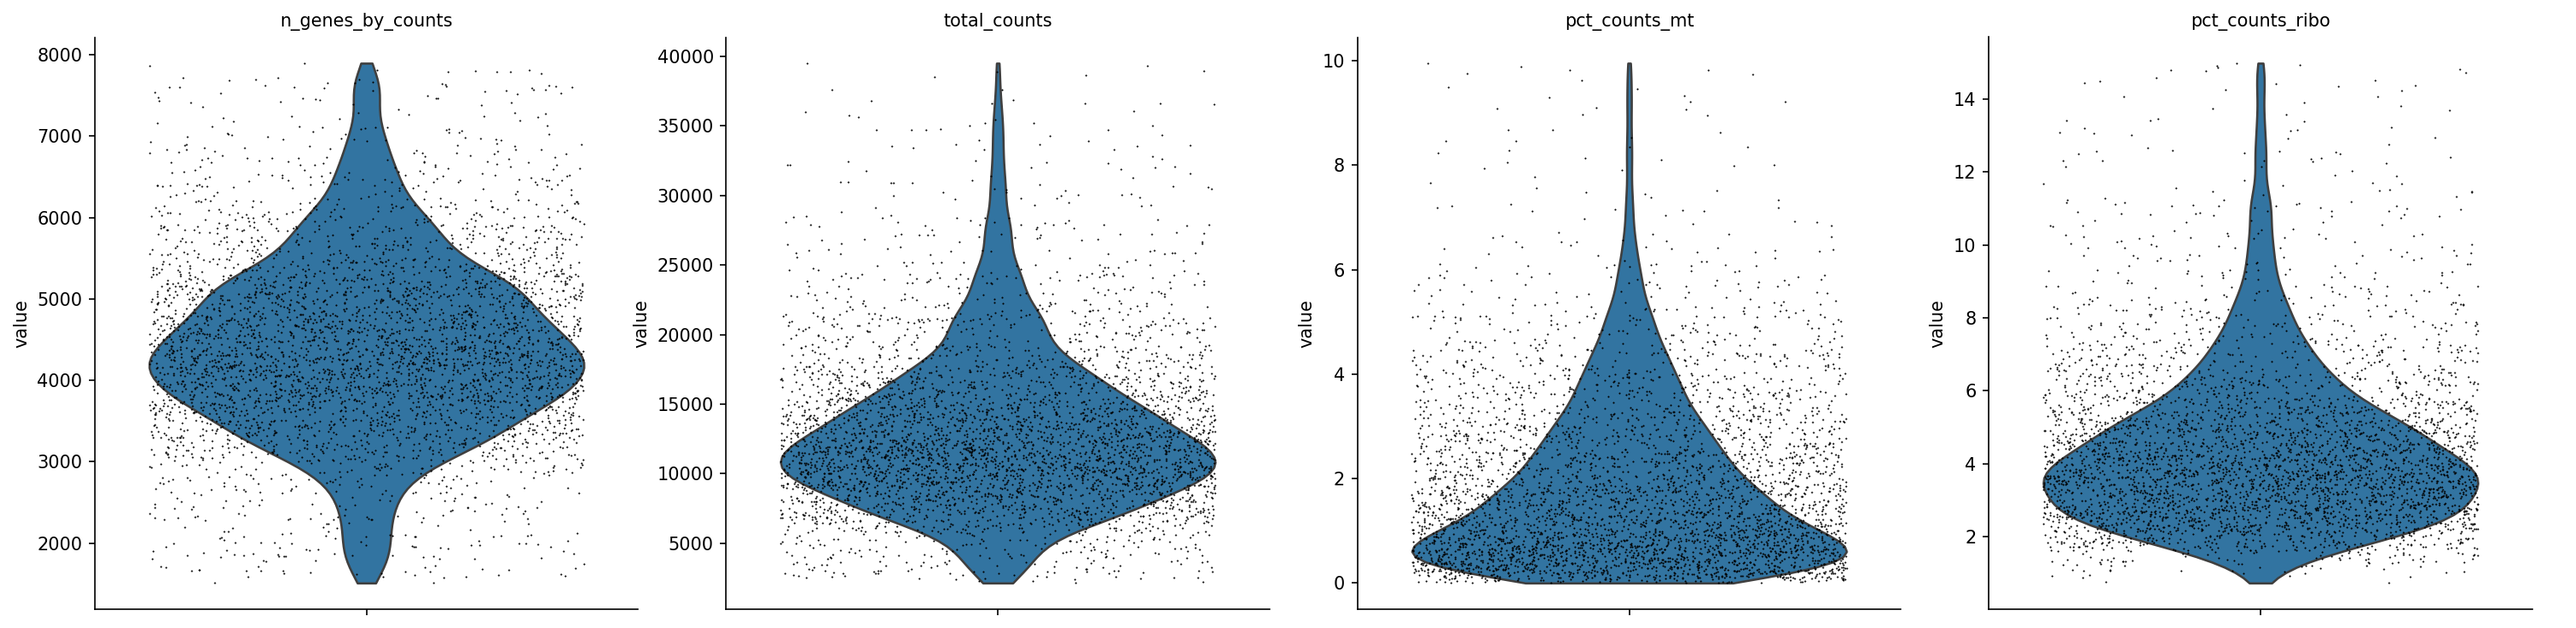

In [62]:
sc.pl.violin(rna_filtered, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo'],
             jitter=0.4, multi_panel=True)

In [63]:
rna_filtered.layers["counts"] = rna_filtered.X.copy()

<positron-console-cell-63>:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.


### Normalization

In [64]:
sc.pp.normalize_total(rna_filtered, target_sum=1e4)
sc.pp.log1p(rna_filtered)

### Feature Selection

We will label highly variable genes that we'll use for downstream analysis.

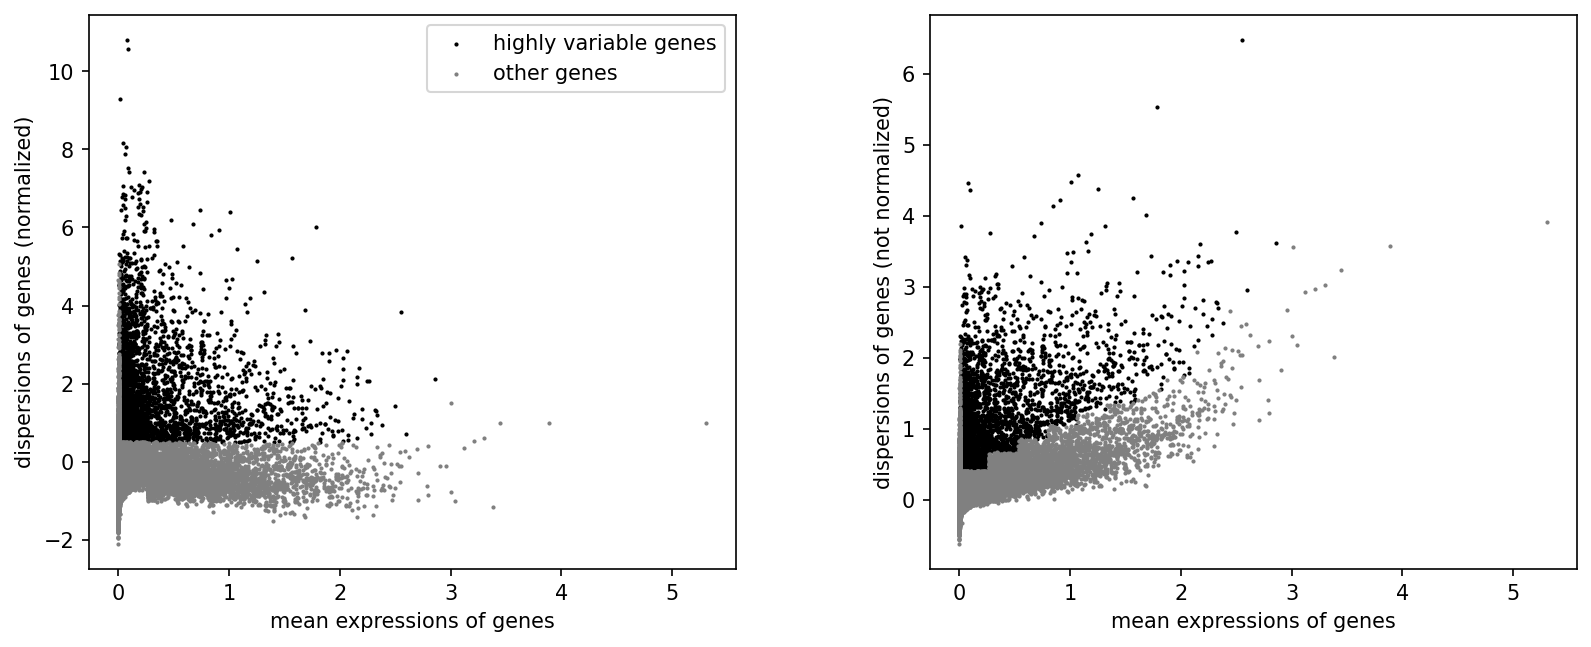

In [65]:
sc.pp.highly_variable_genes(rna_filtered)
sc.pl.highly_variable_genes(rna_filtered)

In [ ]:
# keep_genes = rna_filtered.var["highly_variable"]
# rna_filtered = rna_filtered[:, keep_genes]
# np.sum(rna_filtered.var.highly_variable)

## Analysis

### PCA and Neighborhood Graph

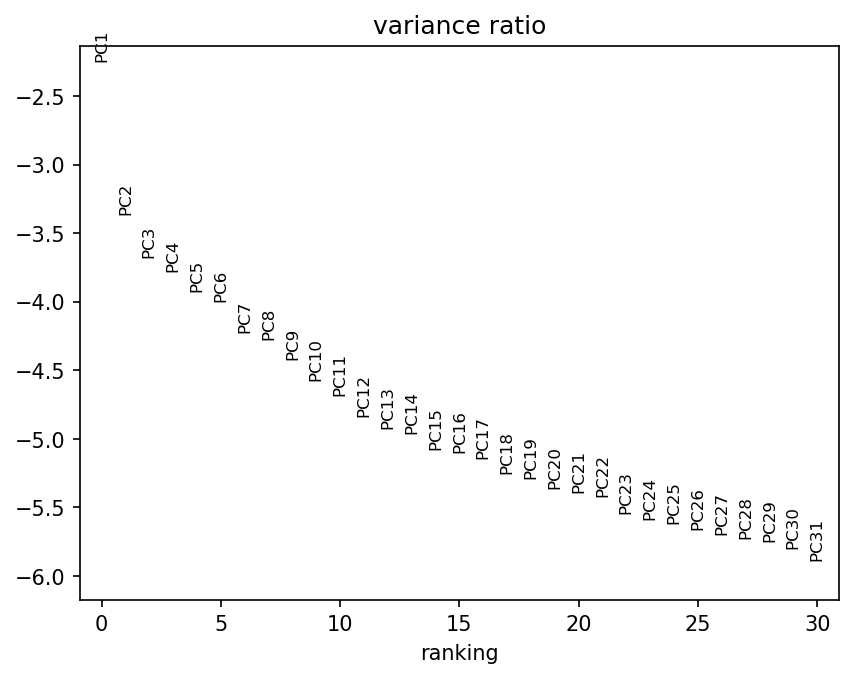

In [66]:
sc.tl.pca(rna_filtered, svd_solver='arpack')
sc.pl.pca_variance_ratio(rna_filtered, log=True)

### Non-linear dimensionality reduction and clustering

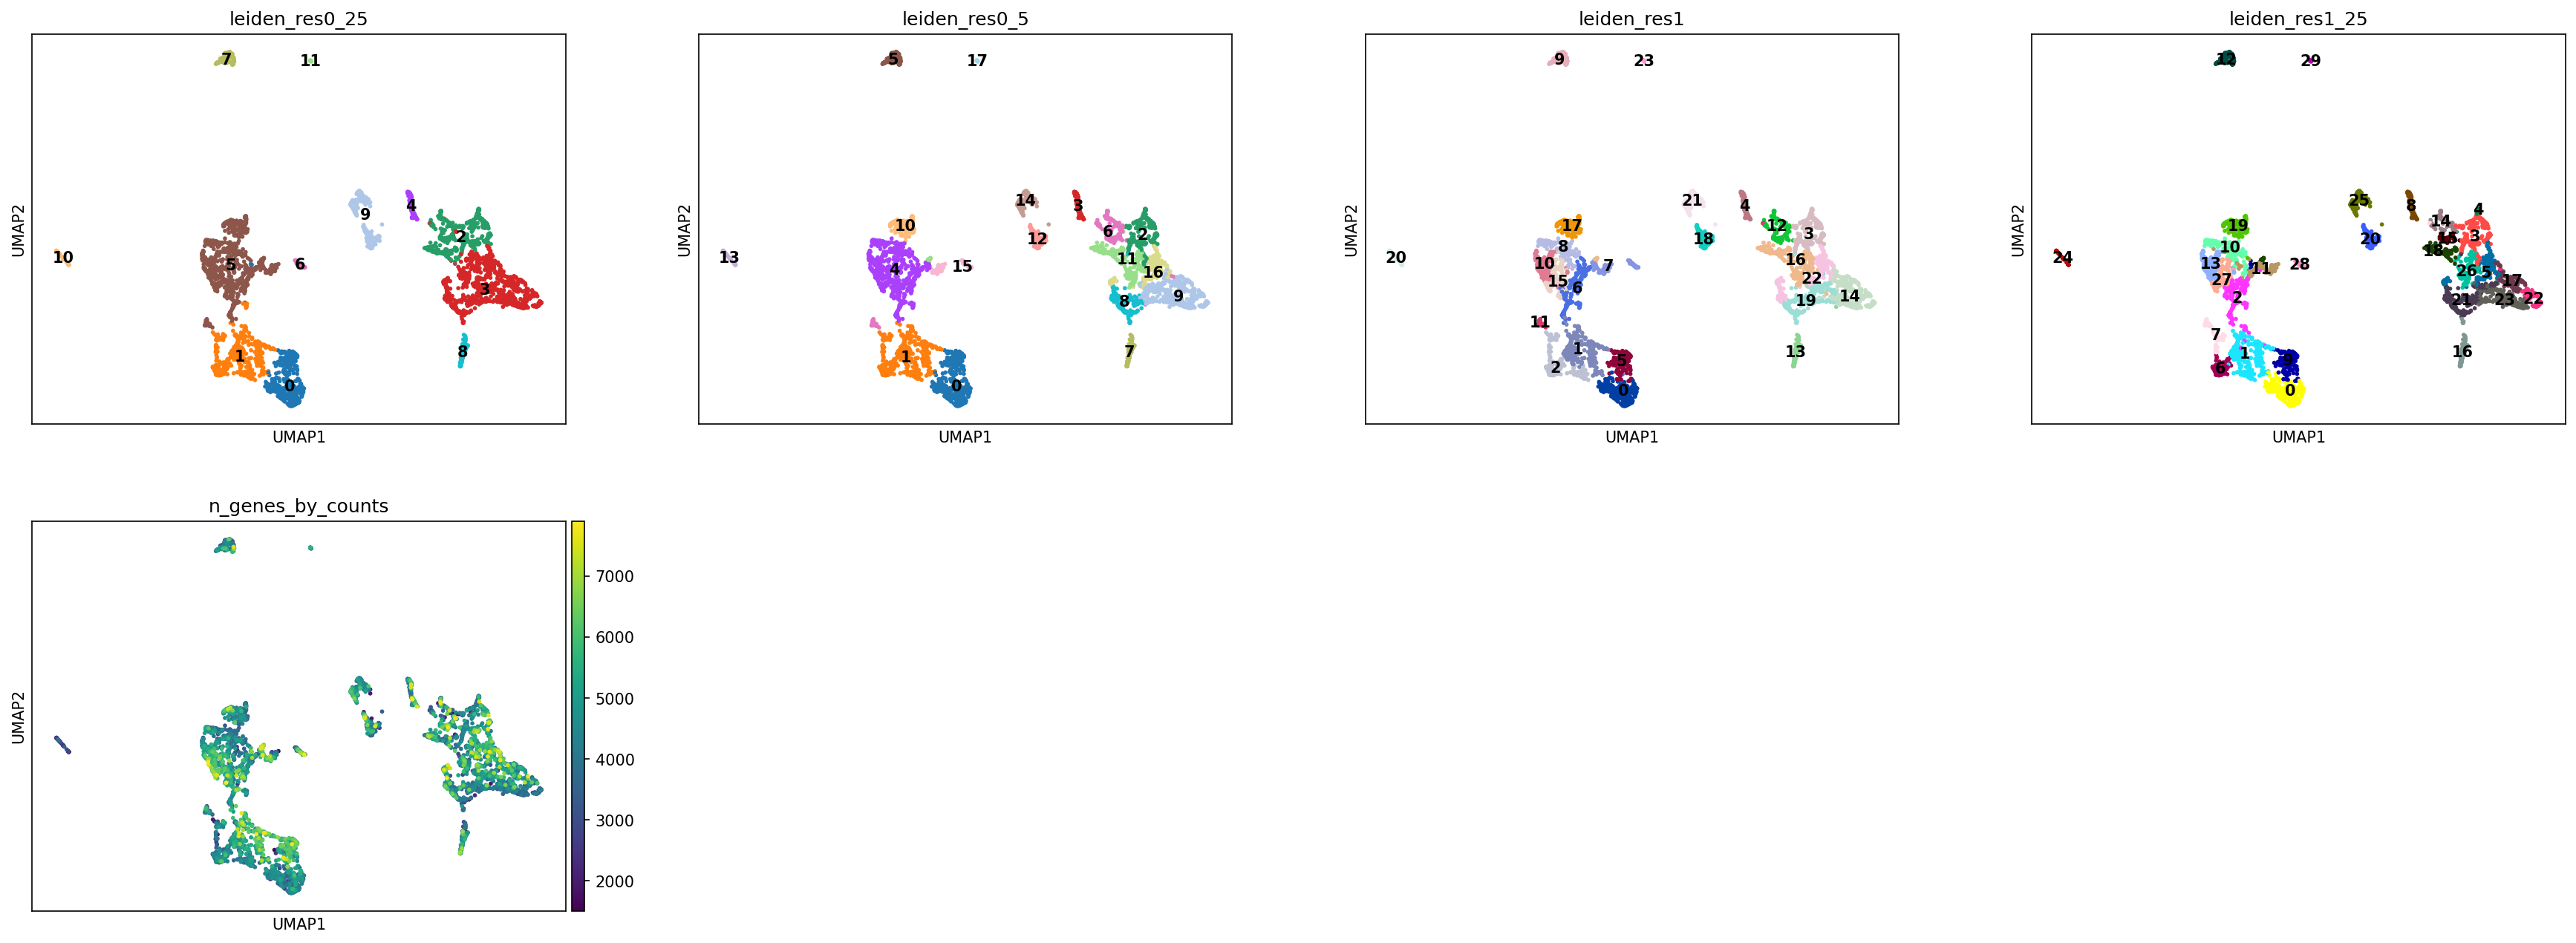

In [67]:
sc.pp.pca(rna_filtered, svd_solver="arpack", mask_var="highly_variable", random_state=0)
sc.pp.neighbors(rna_filtered, n_neighbors=10, n_pcs=10, random_state=0)
sc.tl.umap(rna_filtered, spread=1., min_dist=.1, random_state=11)

sc.tl.leiden(
    rna_filtered, key_added="leiden_res0_25", resolution=0.25, flavor="igraph", n_iterations=2, random_state=0
)
sc.tl.leiden(
    rna_filtered, key_added="leiden_res0_5", resolution=0.5, flavor="igraph", n_iterations=2, random_state=0
)
sc.tl.leiden(
    rna_filtered, key_added="leiden_res1", resolution=1.0, flavor="igraph", n_iterations=2, random_state=0
)
sc.tl.leiden(
    rna_filtered, key_added="leiden_res1_25", resolution=1.25, flavor="igraph", n_iterations=2, random_state=0
)

sc.pl.umap(
    rna_filtered,
    color=["leiden_res0_25", "leiden_res0_5", "leiden_res1", "leiden_res1_25", "n_genes_by_counts"],
    legend_loc="on data",
)

In [68]:
leiden_res = "leiden_res0_5"

## Cell Type Mapping

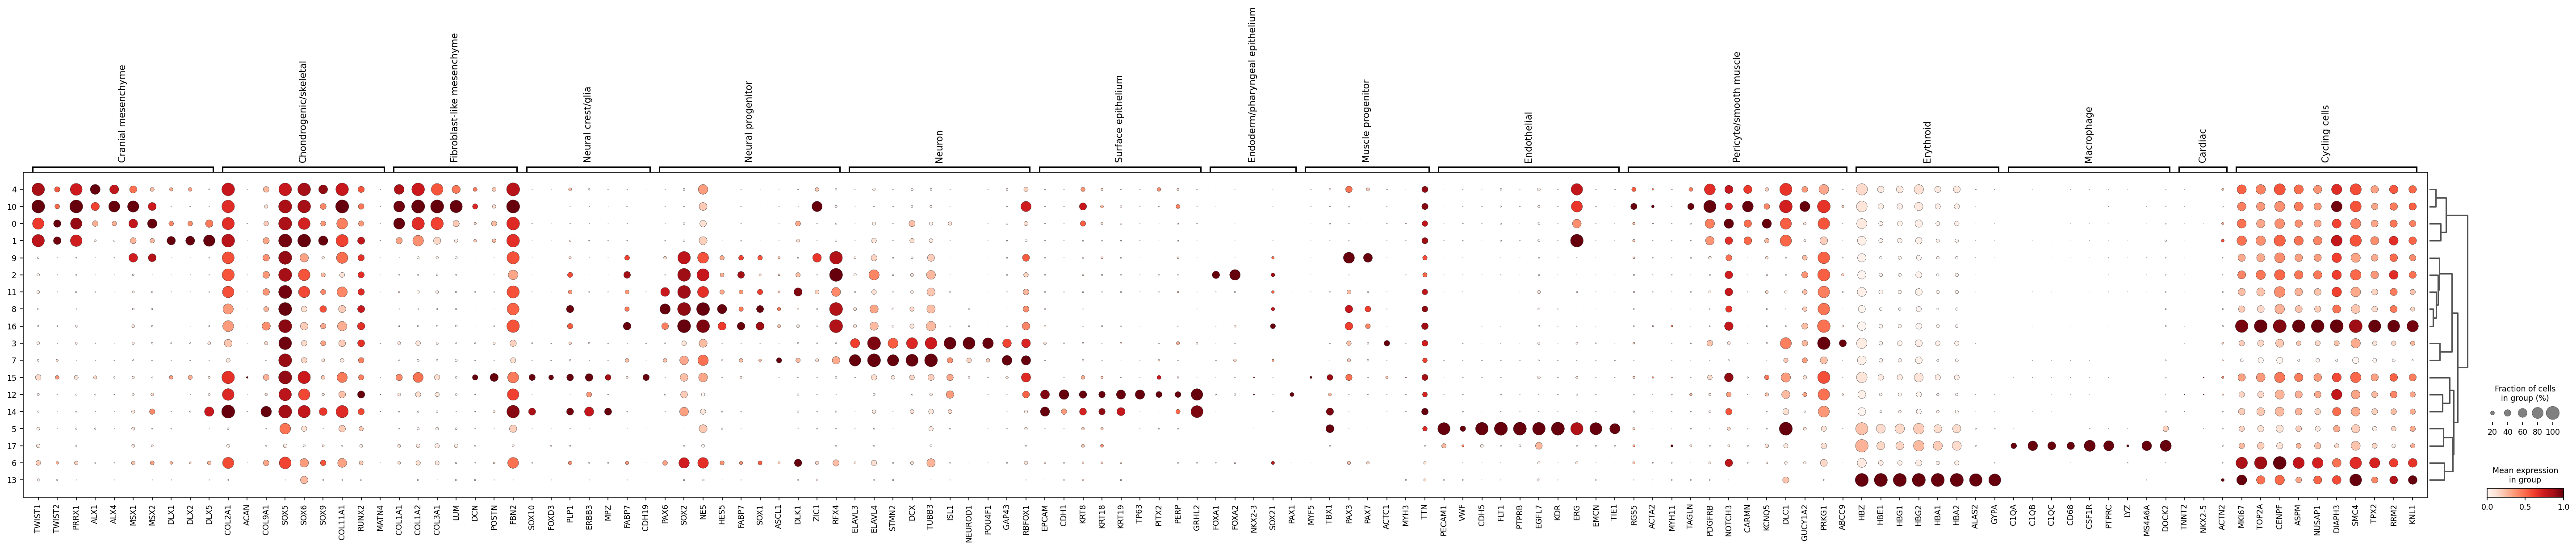

In [69]:
marker_dict = {
    "Cranial mesenchyme": ["TWIST1", "TWIST2", "PRRX1", "ALX1", "ALX4", "MSX1", "MSX2", "DLX1", "DLX2", "DLX5"],
    "Chondrogenic/skeletal": ["COL2A1", "ACAN", "COL9A1", "SOX5", "SOX6", "SOX9", "COL11A1", "RUNX2", "MATN4"],
    "Fibroblast-like mesenchyme": ["COL1A1", "COL1A2", "COL3A1", "LUM", "DCN", "POSTN", "FBN2"],
    "Neural crest/glia": ["SOX10", "FOXD3", "PLP1", "ERBB3", "MPZ", "FABP7", "CDH19"],
    "Neural progenitor": ["PAX6", "SOX2", "NES", "HES5", "FABP7", "SOX1", "ASCL1", "DLK1", "ZIC1", "RFX4"],
    "Neuron": ["ELAVL3", "ELAVL4", "STMN2", "DCX", "TUBB3", "ISL1", "NEUROD1", "POU4F1", "GAP43", "RBFOX1"],
    "Surface epithelium": ["EPCAM", "CDH1", "KRT5", "KRT8", "KRT18", "KRT19", "TP63", "PITX2", "PERP", "GRHL2"],
    "Endoderm/pharyngeal epithelium": ["FOXA1", "FOXA2", "NKX2-3", "SOX21", "PAX1"],
    "Muscle progenitor": ["MYF5", "MYOD1", "MYOG", "TBX1", "PAX3", "PAX7", "ACTC1", "MYH3", "TTN"],
    "Endothelial": ["PECAM1", "VWF", "CDH5", "FLT1", "PTPRB", "EGFL7", "KDR", "ERG", "EMCN", "TIE1"],
    "Pericyte/smooth muscle": ["RGS5", "ACTA2", "MYH11", "TAGLN", "PDGFRB", "NOTCH3", "CARMN", "KCNQ5", "DLC1", "GUCY1A2", "PRKG1", "ABCC9"],
    "Erythroid": ["HBZ", "HBE1", "HBG1", "HBG2", "HBA1", "HBA2", "ALAS2", "GYPA"],
    "Macrophage": ["C1QA", "C1QB", "C1QC", "CD68", "CSF1R", "PTPRC", "LYZ", "MS4A6A", "DOCK2"],
    "Cardiac": ["TNNT2", "MYH6", "MYL7", "NKX2-5", "ACTN2"],
    "Cycling cells": ["MKI67", "TOP2A", "CENPF", "ASPM", "NUSAP1", "DIAPH3", "SMC4", "TPX2", "RRM2", "KNL1"],
}

# Keep only genes present in the RNA object
marker_dict_present = {
    group: [g for g in genes if g in rna_filtered.var_names]
    for group, genes in marker_dict.items()
}

# Remove empty groups
marker_dict_present = {
    group: genes
    for group, genes in marker_dict_present.items()
    if len(genes) > 0
}

sc.pl.dotplot(
    rna_filtered,
    var_names=marker_dict_present,
    groupby=leiden_res,
    standard_scale="var",
    dendrogram=True,
    swap_axes=False
)

In [70]:
# only keep genes that exist in your data
markers = {k: [g for g in v if g in rna_filtered.var_names] for k, v in marker_dict.items()}

dp = sc.pl.dotplot(
    rna_filtered, markers, groupby=leiden_res,  # swap in whichever resolution you used
    standard_scale="var", return_fig=True,
)

mean_expr = dp.dot_color_df   # color: mean expression (scaled if standard_scale is set)
frac_expr = dp.dot_size_df    # size: fraction of cells expressing

marker_gene_dir = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/dev/notebooks/muon_preprocessing/hg38/marker_gene_by_cluster")
sample_marker_gene_dir = marker_gene_dir / f"{DATASET_NAME}_{SAMPLE_NAME}"
sample_marker_gene_dir.mkdir(parents=True, exist_ok=True)

import json
with open(sample_marker_gene_dir / "cell_type_markers.json", "w") as f:
    json.dump(markers, f, indent=2)
mean_expr.to_csv(sample_marker_gene_dir / "dotplot_mean_expr.csv")
frac_expr.to_csv(sample_marker_gene_dir / "dotplot_frac_expr.csv")

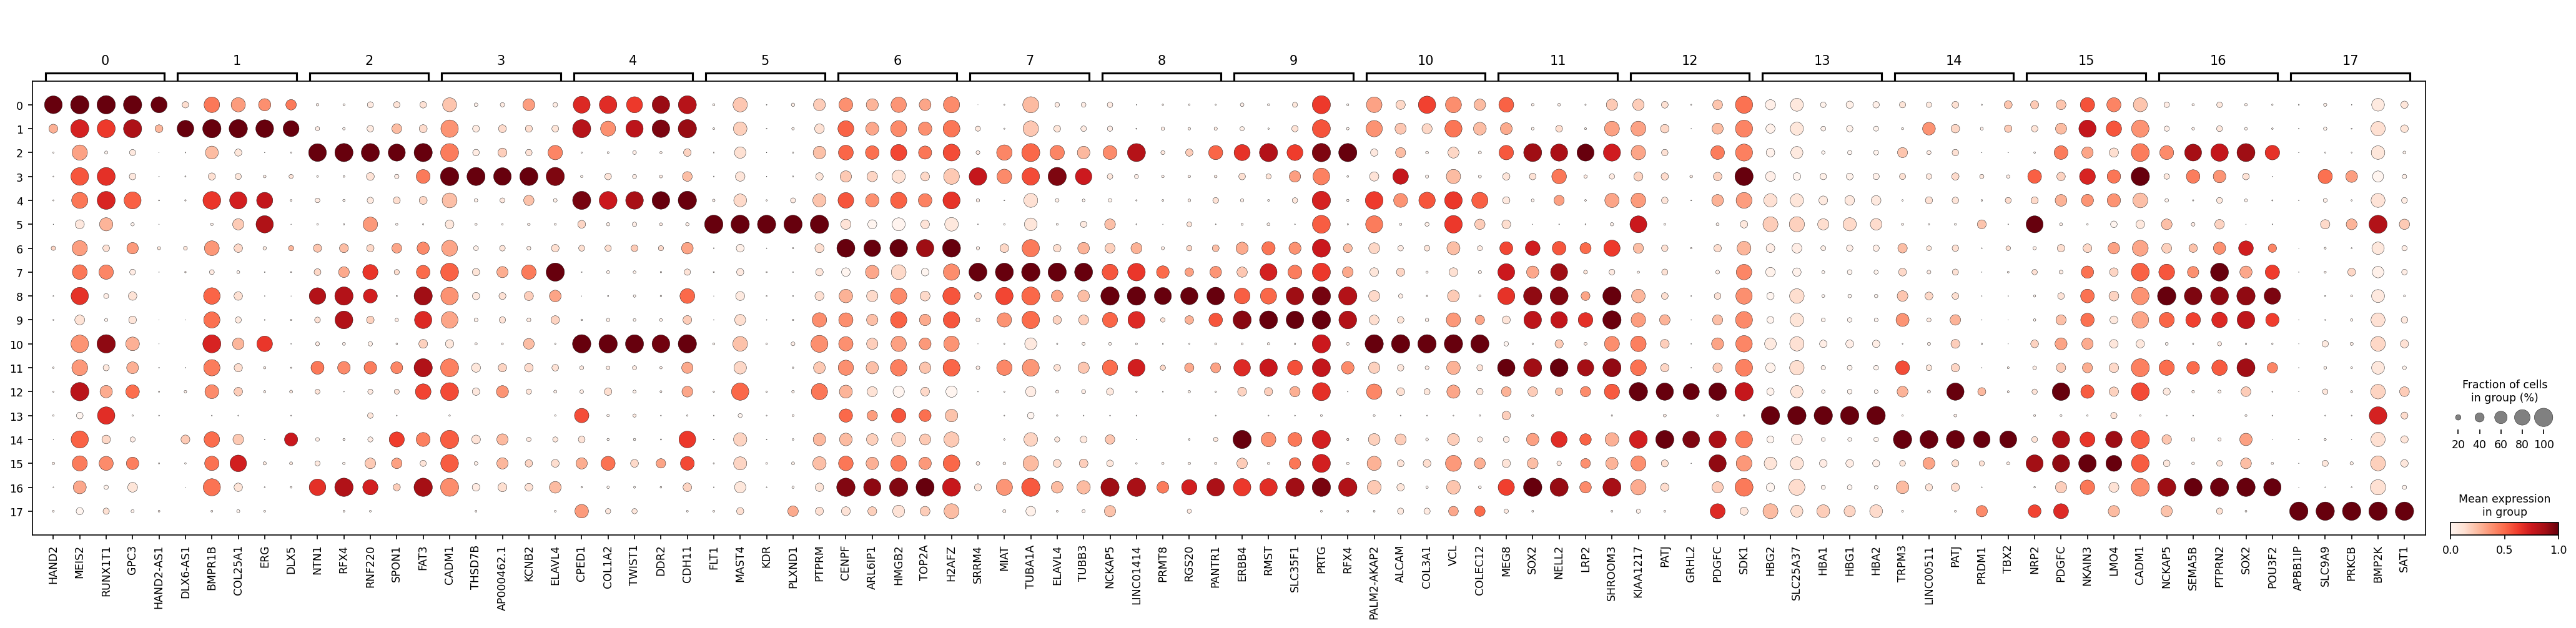

In [71]:
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="DataFrame is highly fragmented.*",
        category=pd.errors.PerformanceWarning,
    )
    sc.tl.rank_genes_groups(rna_filtered, groupby=leiden_res, method="wilcoxon", use_raw=False, pts=True)

    de = sc.get.rank_genes_groups_df(rna_filtered, group=None)
    top15 = (
        de[(de["logfoldchanges"] > 1) & (de["pvals_adj"] < 0.05)]
        .sort_values(["group", "scores"], ascending=[True, False])
        .groupby("group", observed=True)
        .head(15)
    )
    top15.to_csv(sample_marker_gene_dir / "Top15_Markers_By_Cluster.csv", index=False)
    (
        top15.groupby("group", observed=True)["names"]
        .agg(", ".join)
        .rename("top15_genes")
        .to_csv(sample_marker_gene_dir / "Top15_Markers_By_Cluster_grouped.csv")
    )


sc.pl.rank_genes_groups_dotplot(rna_filtered, n_genes=5, groupby=leiden_res, standard_scale="var", dendrogram=False)

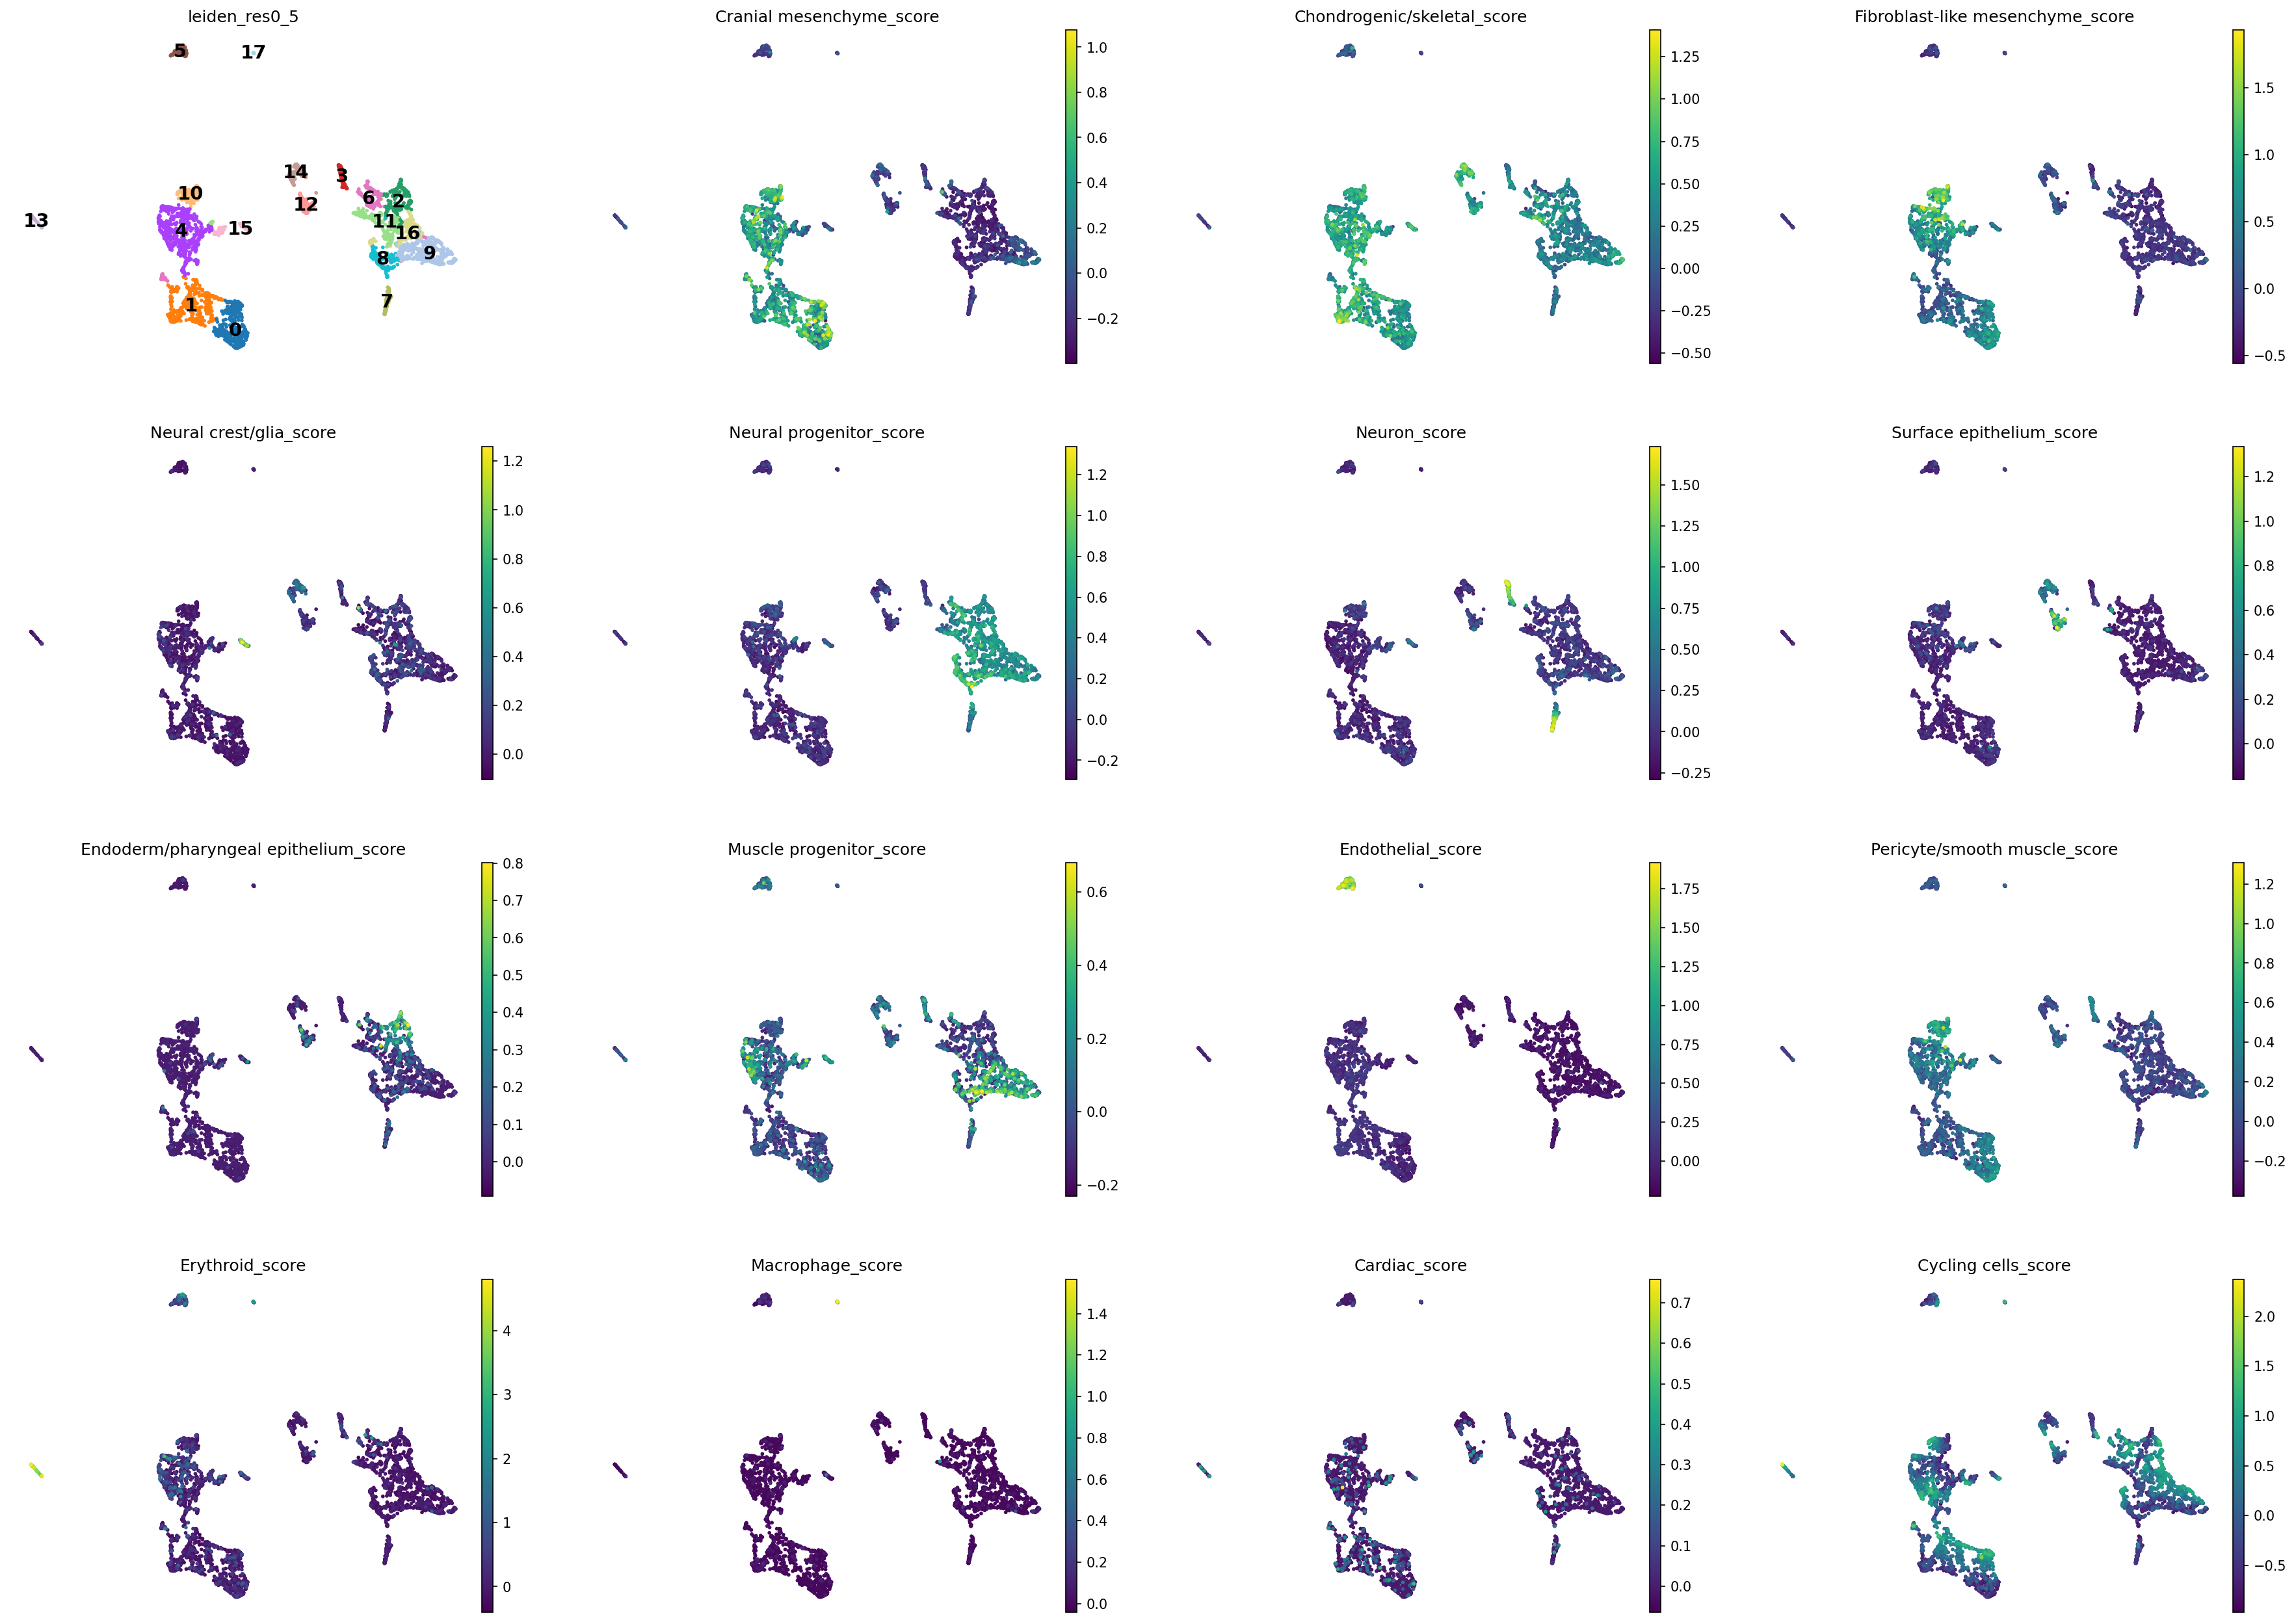

In [72]:
score_cols = [leiden_res]

for cell_type, genes in marker_dict_present.items():
    score_col = f"{cell_type}_score"
    sc.tl.score_genes(
        rna_filtered,
        gene_list=genes,
        score_name=score_col,
        use_raw=False,  # use the expression in rna_filtered.X
    )
    score_cols.append(score_col)

sc.pl.umap(
    rna_filtered,
    color=score_cols,
    ncols=4,
    cmap="viridis",
    frameon=False,
    legend_loc="on data",
    legend_fontsize=14,
)

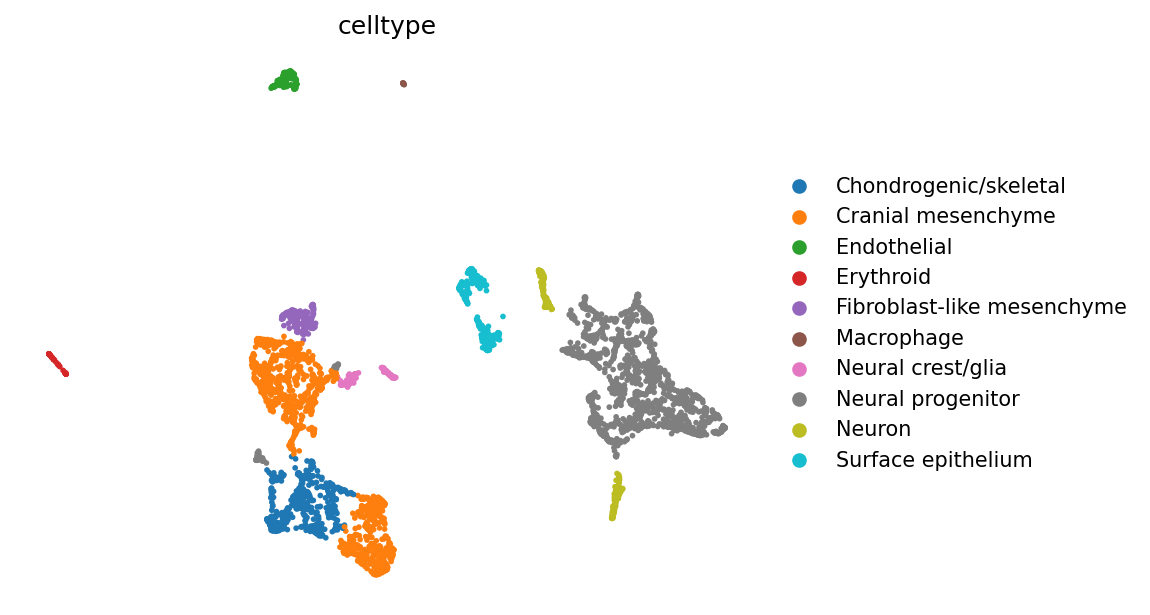

In [73]:
# Leiden clusters (leiden_res0_5) per cell type for THIS sample; fill in after reading the dotplot and
# score UMAPs above. Unlisted clusters stay unlabeled (NaN).
celltype_map = {
    "Cranial mesenchyme": ["0", "4"],
    "Chondrogenic/skeletal": ["1"],
    "Fibroblast-like mesenchyme": ["10"],
    "Neural crest/glia": ["15"],
    "Neural progenitor": ["2", "6", "8", "9", "11", "16"],
    "Neuron": ["3", "7"],
    "Surface epithelium": ["12", "14"],
    "Endoderm/pharyngeal epithelium": [],
    "Muscle progenitor": [],
    "Endothelial": ["5"],
    "Pericyte/smooth muscle": [],
    "Erythroid": ["13"],
    "Macrophage": ["17"],
    "Cardiac": [],
}

cluster_to_celltype = {
    str(c): ct for ct, clusters in celltype_map.items() for c in clusters
}

rna_filtered.obs["celltype"] = (
    rna_filtered.obs[leiden_res]
    .astype(str)
    .map(cluster_to_celltype)
    .astype("category")
)

# Plot UMAP with cell type labels
sc.pl.umap(
    rna_filtered,
    color=["celltype"],
    vmax="p99",
    frameon=False,
)

In [74]:
for celltype in rna_filtered.obs["celltype"].cat.categories:
    print(f"{celltype}: {rna_filtered.obs[rna_filtered.obs['celltype'] == celltype].shape[0]}")

Chondrogenic/skeletal: 508
Cranial mesenchyme: 1106
Endothelial: 133
Erythroid: 58
Fibroblast-like mesenchyme: 168
Macrophage: 21
Neural crest/glia: 111
Neural progenitor: 1407
Neuron: 224
Surface epithelium: 275


## Saving progress to disk

In [75]:
mu.write(str(SAMPLE_PROCESSED_DATA_DIR / f"{SAMPLE_NAME}.h5mu/rna"), rna_filtered)
print(f"Saved RNA data to {SAMPLE_PROCESSED_DATA_DIR / f'{SAMPLE_NAME}.h5mu/rna'}")

Saved RNA data to /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/data/processed/hg38/GSE249497_embryonic_orofacial/CS13_01/CS13_01.h5mu/rna


---

# ATAC

In [76]:
atac = mdata.mod['atac']
atac  # an AnnData object

AnnData object with n_obs × n_vars = 4396 × 168161
    var: 'chrom', 'start', 'end'

## Preprocessing

### QC

Filter out cells with too few peaks and peaks detected in too few cells.

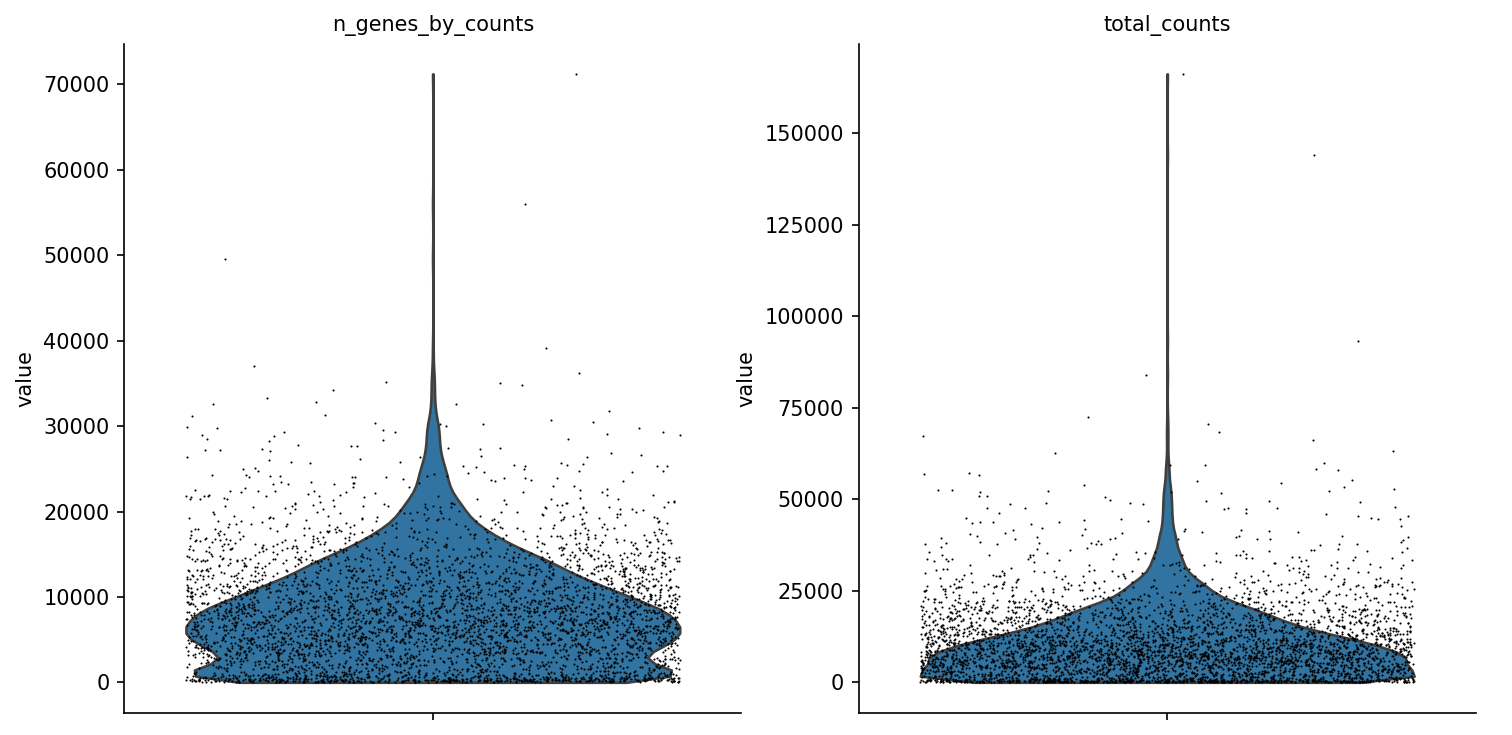

In [77]:
sc.pp.calculate_qc_metrics(atac, percent_top=None, log1p=False, inplace=True)
sc.pl.violin(atac, ['n_genes_by_counts', 'total_counts'], jitter=0.4, multi_panel=True)

In [78]:
atac_filtered = atac.copy()

In [79]:
# Thresholds copied from the vena cava notebook; set them for this library from the violin plots above.
print(f"Cells before filtering: {atac_filtered.n_obs}")
mu.pp.filter_obs(atac_filtered, 'n_genes_by_counts', lambda x: (x >= 500) & (x <= 25000))
mu.pp.filter_obs(atac_filtered, 'total_counts', lambda x: (x <= 50000) & (x >= 500))

mu.pp.filter_var(atac_filtered, 'n_cells_by_counts', lambda x: x >= 10)
print(f"Cells after filtering: {atac_filtered.n_obs}")


Cells before filtering: 4396
Cells after filtering: 3938


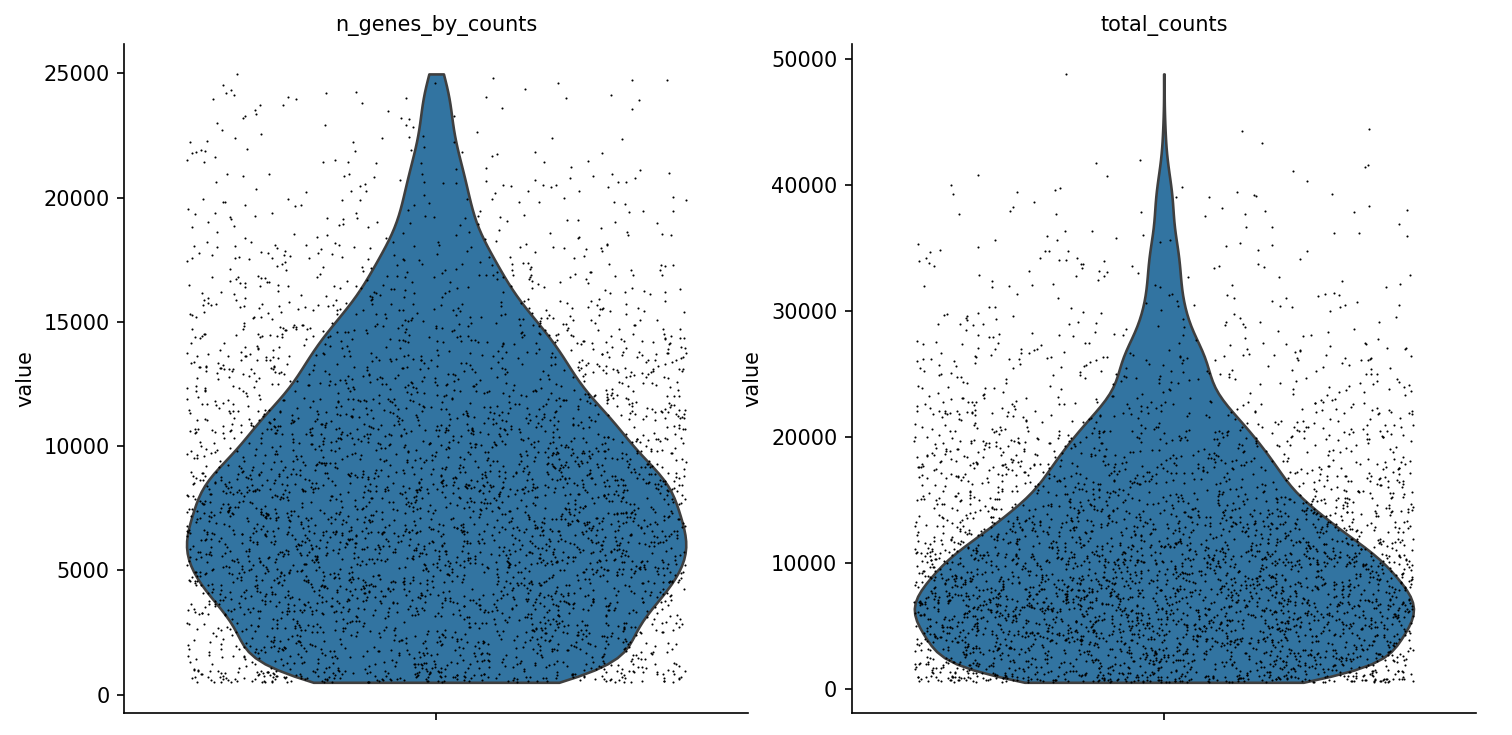

In [80]:
sc.pl.violin(atac_filtered, ['n_genes_by_counts', 'total_counts'], jitter=0.4, multi_panel=True)

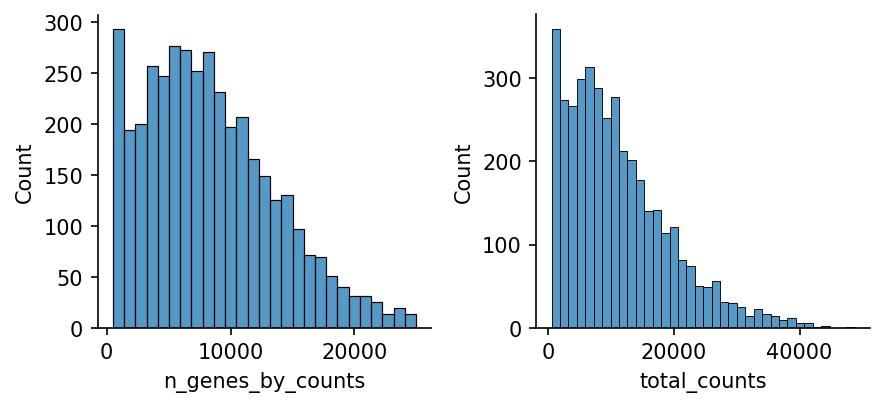

In [81]:
mu.pl.histogram(atac_filtered, ['n_genes_by_counts', 'total_counts'])

### ATAC-specific QC
There are a few expectations about how ATAC-seq data looks like as noted in the [hitchhiker’s guide to ATAC-seq data analysis](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-020-1929-3#citeas) for instance


#### Nucleosome Signal

Fragment size distribution typically reflects nucleosome binding pattern showing enrichment around values corresponding to fragments bound to a single nucleosome (between 147 bp and 294 bp) as well as nucleosome-free fragments (shorter than 147 bp).

Index file not found. Creating index file...
['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr20', 'chr21', 'chr22', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7']
{'fragments': '/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/GSE249497_embryonic_orofacial_10x_raw/CS13_01/fragments.tsv.gz'}
/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/GSE249497_embryonic_orofacial_10x_raw/CS13_01/fragments.tsv.gz
chr1:1-2000001 chr1	10067	10198	CATAGGTTCGATATTG-1	1


Fetching Regions...: 100%|██████████| 1/1 [00:01<00:00,  1.11s/it]


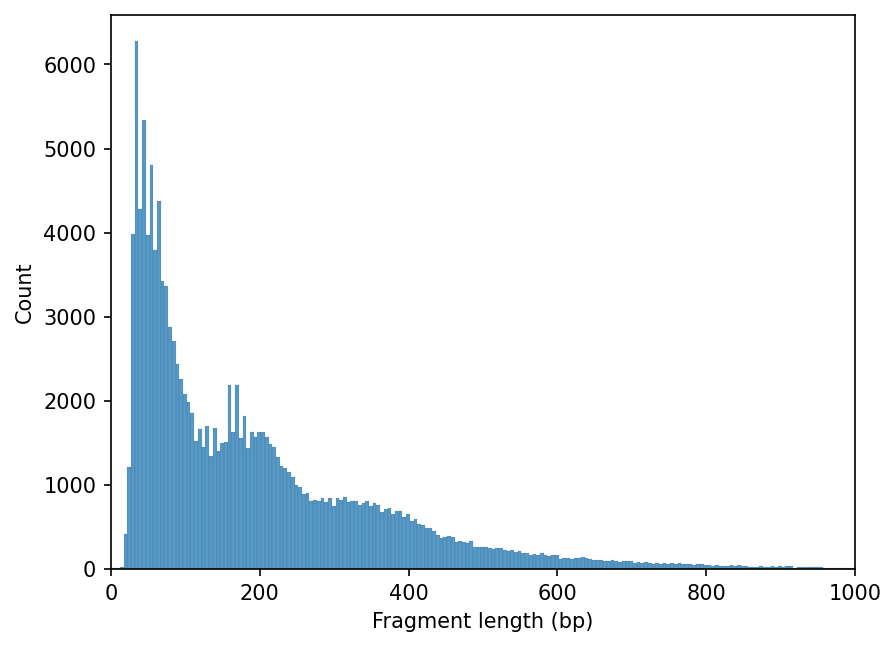

In [82]:
if frag_path is not None:
    index_file = str(frag_path) + ".tbi"

    if Path(index_file).exists():
        print("Found index:", index_file)

    else:
        # Index the fragment file
        print("Index file not found. Creating index file...")
        pysam.tabix_index(
            str(frag_path),
            preset="bed",
            force=True
        )
        index_file = str(frag_path) + ".tbi"

    # Create the index file for the fragments
    tbx = pysam.TabixFile(str(frag_path))
    print(tbx.contigs[:20])

    # register the fragment file with the ATAC AnnData
    ac.tl.locate_fragments(atac_filtered, fragments=str(frag_path))

    print(atac_filtered.uns["files"])
    print(atac_filtered.uns["files"]["fragments"])
    # optional grouping column if you want one
    atac_filtered.obs["NS"] = 1

    def find_nonempty_region(tbx, chrom="chr1", window=2_000_000, max_end=200_000_000):
        for start in range(1, max_end, window):
            rows = list(tbx.fetch(chrom, start, start + window))
            if rows:
                return f"{chrom}:{start}-{start+window}", rows[0]
        return None, None

    region, example = find_nonempty_region(tbx, chrom="chr1")
    print(region, example)

    ac.pl.fragment_histogram(atac_filtered, region=region)
else:
    print("No fragment file provided, skipping fragment histogram plotting.")

Reading Fragments: 100%|██████████| 1000000/1000000 [00:04<00:00, 243509.11it/s]


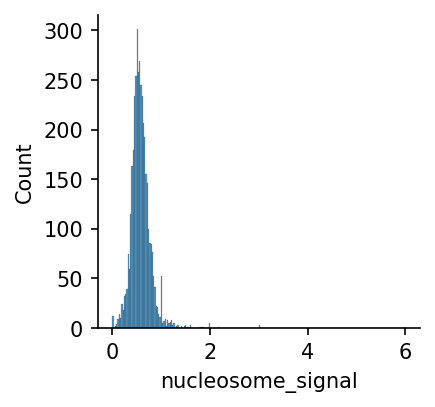

In [83]:
ac.tl.nucleosome_signal(atac_filtered, n=1e6)
mu.pl.histogram(atac_filtered, "nucleosome_signal", kde=False)

In [84]:
# Replace with your reference annotation; .gtf.gz also works.
gtf_path = "/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/data/genome_data/genome_annotation/hg38/Homo_sapiens.GRCh38.113.gtf.gz"

gtf = pd.read_csv(
    gtf_path,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "Chromosome", "Source", "Feature", "Start", "End",
        "Score", "Strand", "Frame", "Attributes",
    ],
    dtype={"Chromosome": str},
)

genes = gtf.loc[gtf["Feature"].eq("gene")].copy()

,Chromosome,Start,End
0,chr1,3069167,3069168
1,chr1,5307393,5307394
2,chr1,2413796,2413797


Fetching Regions...: 100%|██████████| 1000/1000 [00:04<00:00, 212.71it/s]
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


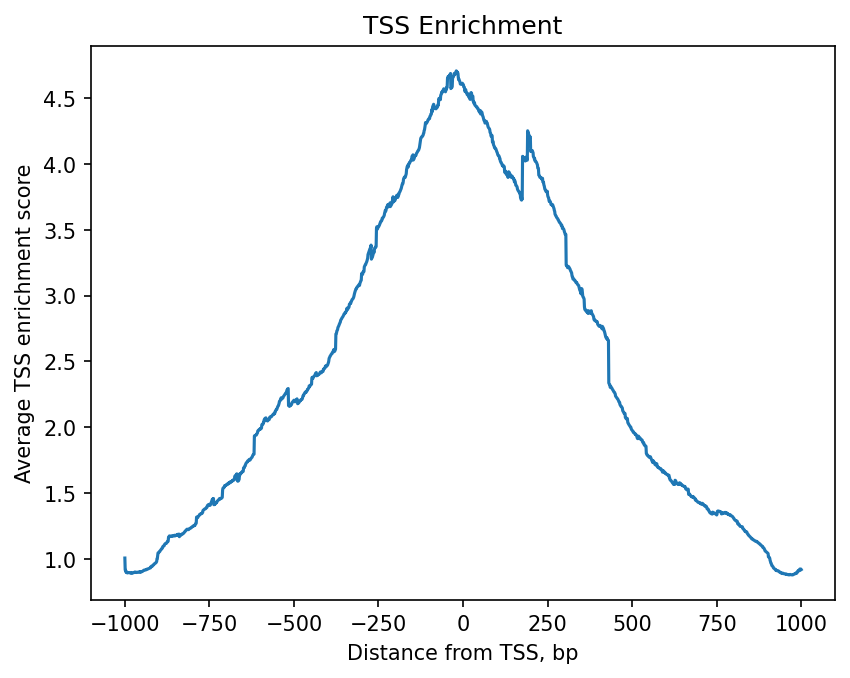

In [85]:
# Get strand-specific TSS positions and convert from 1-based to 0-based.
tss_position = np.where(
    genes["Strand"].eq("+"),
    genes["Start"] - 1,
    genes["End"] - 1,
).astype(int)

features = pd.DataFrame({
    "Chromosome": genes["Chromosome"].astype(str).to_numpy(),
    "Start": tss_position,
    "End": tss_position + 1,
}).drop_duplicates()

# If your fragments use chr1, chr2, ..., chrX, chrY, chrM,
# convert Ensembl's primary chromosome names to match:
chrom_map = {
    str(c): f"chr{c}"
    for c in [*range(1, 23), "X", "Y"]
}
chrom_map["MT"] = "chrM"

# Remove this line if your fragments use Ensembl names (1, 2, ..., MT).
features["Chromosome"] = features["Chromosome"].replace(chrom_map)

display(features.head(3))

ac.tl.locate_fragments(mdata, fragments=str(frag_path))

tss = ac.tl.tss_enrichment(
    mdata,
    features=features,
    n_tss=1000,
    random_state=0,
)

ac.pl.tss_enrichment(tss)

### Normalization

In [86]:
# Save original counts
atac_filtered.layers["counts"] = atac_filtered.X

In [87]:
# ac.pp.tfidf(atac_filtered, scale_factor=1e4)

Here we will use the same log-normalisation and PCA that we are used to from scRNA-seq analysis. We notice on this data it yields PC & UMAP spaces similar to the one generated on scRNA-seq counts.

In [88]:
sc.pp.normalize_per_cell(atac_filtered, counts_per_cell_after=1e4)
sc.pp.log1p(atac_filtered)

<positron-console-cell-88>:1: FutureWarning: Use sc.pp.normalize_total instead
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:590: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


In [89]:
ac.tl.lsi(atac_filtered)

atac_filtered.obsm['X_lsi'] = atac_filtered.obsm['X_lsi'][:,1:]
atac_filtered.varm["LSI"] = atac_filtered.varm["LSI"][:,1:]
atac_filtered.uns["lsi"]["stdev"] = atac_filtered.uns["lsi"]["stdev"][1:]

### PCA

For this notebook, we are using PCA on the log-normalised counts in atac.X as described above.

### Neighbors

In [90]:
sc.pp.neighbors(atac_filtered, use_rep="X_lsi", n_neighbors=10, n_pcs=30, random_state=0)

### Non-linear dimensionality reduction and clustering

To stay comparable to the gene expression notebook, we will use leiden to cluster cells. We’ll use UMAP latent space for visualisation below.

In [91]:
sc.tl.umap(atac_filtered)
sc.tl.leiden(atac_filtered, flavor="igraph", n_iterations=2, random_state=0)

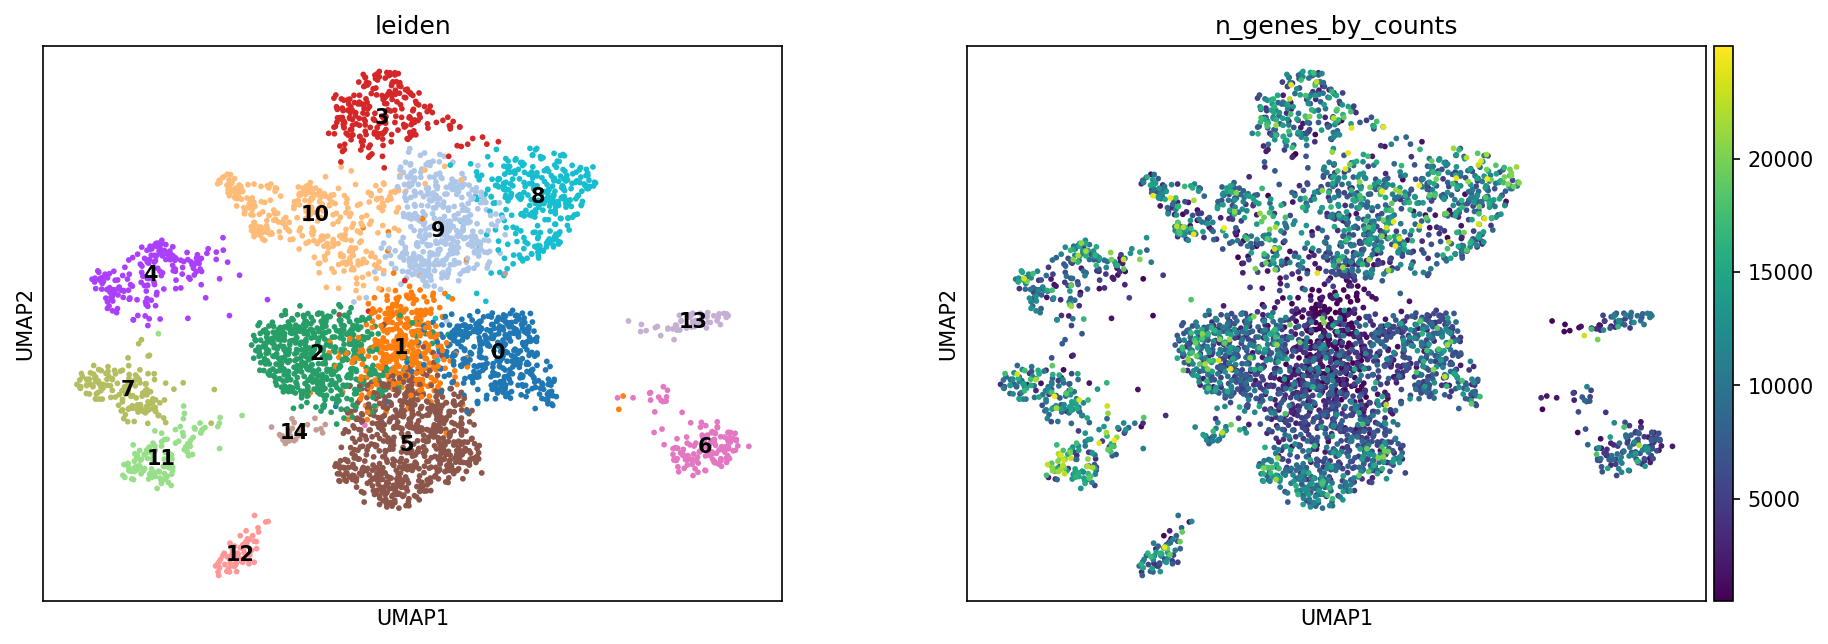

In [92]:
sc.pl.umap(atac_filtered, color=["leiden", "n_genes_by_counts"], legend_loc="on data")

## Saving progress to disk

In [93]:
mu.write(str(SAMPLE_PROCESSED_DATA_DIR / f"{SAMPLE_NAME}.h5mu/atac"), atac_filtered)

---

In [7]:
# Reload the filtered RNA and ATAC saved above; mdata still holds the raw input until this runs.
mdata = mu.read(str(SAMPLE_PROCESSED_DATA_DIR / f"{SAMPLE_NAME}.h5mu"))
mu.pp.intersect_obs(mdata)
mdata

/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1403: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1275: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:

MuData object with n_obs × n_vars = 3690 × 192508
  obs:	'dataset', 'library'
  var:	'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
  uns:	'source'
  2 modalities
    rna:	3690 x 24347
      obs:	'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1', 'leiden_res1_25', 'Cranial mesenchyme_score', 'Chondrogenic/skeletal_score', 'Fibroblast-like mesenchyme_score', 'Neural crest/glia_score', 'Neural progenitor_score', 'Neuron_score', 'Surface epithelium_score', 'Endoderm/pharyngeal epithelium_score', 'Muscle progenitor_score', 'Endothelial_score', 'Pericyte/smooth muscle_score', 'Erythroid_score', 'Macrophage_score', 'Cardiac_score', 'Cycling cells_score', 'celltype'
      var:	'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
      uns:	'celltype_colors', 'dendrogram_leiden_res0_5', 'hvg', 'leiden_res0_25', 'leiden_res0_25_colors', 'leiden_res0_5', 'leiden_res0_5_colors', 'leiden_res1', 'leiden_res1_25', 'leiden_res1_25_colors', 'leiden_res1_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'scrublet', 'umap'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    atac:	3690 x 168161
      obs:	'n_genes_by_counts', 'total_counts', 'NS', 'nucleosome_signal', 'n_counts', 'leiden'
      var:	'chrom', 'start', 'end', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
      uns:	'files', 'leiden', 'leiden_colors', 'log1p', 'lsi', 'neighbors', 'umap'
      obsm:	'X_lsi', 'X_umap'
      varm:	'LSI'
      layers:	'counts'
      obsp:	'connectivities', 'distances'

In [8]:

MAX_PEAK_DISTANCE = 100_000
TSS_DECAY = 20_000
NEAREST_GENE_ONLY = False


def format_peaks(peak_ids: pd.Index | pd.Series) -> pd.DataFrame:
    """Parse peak IDs such as chr1:100-200 or chr1-100-200."""
    peak_ids = pd.Index(peak_ids).astype(str)
    peak_series = pd.Series(peak_ids, index=peak_ids, name="original_peak_id")

    valid_chr = peak_series.str.contains("chr", regex=False, na=False)
    peak_series = peak_series[valid_chr]

    if peak_series.empty:
        raise ValueError("No peak IDs containing 'chr' were found.")

    parsed = peak_series.str.extract(
        r".*?(?P<chrom>chr[^\s:-]+)(?::|-)(?P<start>\d+)-(?P<end>\d+)\s*$"
    )
    parsed.index = peak_series.index

    missing = parsed[["chrom", "start", "end"]].isna().any(axis=1)
    if missing.any():
        bed_like = peak_series.loc[missing].str.extract(
            r"^\s*(?P<chrom>\S+)\s+(?P<start>\d+)\s+(?P<end>\d+)(?:\s|$)"
        )
        bed_like.index = peak_series.loc[missing].index
        parsed.loc[missing, ["chrom", "start", "end"]] = bed_like[
            ["chrom", "start", "end"]
        ]

    malformed = parsed[["chrom", "start", "end"]].isna().any(axis=1)
    if malformed.any():
        bad = peak_series.loc[malformed].head(3).tolist()
        raise ValueError(f"Malformed peak IDs, e.g. {bad}")

    peak_df = pd.DataFrame(
        {
            "chrom": parsed["chrom"].astype(str),
            "start": pd.to_numeric(parsed["start"]).astype(np.int64),
            "end": pd.to_numeric(parsed["end"]).astype(np.int64),
        },
        index=parsed.index,
    )

    invalid_coordinates = peak_df["end"] <= peak_df["start"]
    if invalid_coordinates.any():
        bad = peak_df.index[invalid_coordinates].tolist()[:3]
        raise ValueError(f"Peaks have end <= start, e.g. {bad}")

    # This preserves the exact ATAC var_name for mapping results back into .var.
    peak_df["peak_id"] = peak_df.index.astype(str)

    return peak_df.reset_index(drop=True)


def find_genes_near_peaks(
    peak_bed: pybedtools.BedTool,
    tss_bed: pybedtools.BedTool,
    distance_cutoff: int,
) -> pd.DataFrame:
    """
    Find peak-TSS pairs within distance_cutoff.

    Assumes tss_bed has four columns:
        chromosome, start, end, gene_id

    Returns one row per (peak, gene) pair, sorted by peak then distance.
    """
    overlaps = peak_bed.window(tss_bed, w=distance_cutoff)

    columns = [
        "peak_chr",
        "peak_start",
        "peak_end",
        "peak_id",
        "gene_chr",
        "gene_start",
        "gene_end",
        "target_id",
    ]

    hits = overlaps.to_dataframe(names=columns, low_memory=False)

    if hits.empty:
        return pd.DataFrame(
            columns=[
                "peak_id",
                "target_id",
                "TSS_dist",
                "TSS_dist_score",
            ]
        )

    numeric_columns = [
        "peak_start",
        "peak_end",
        "gene_start",
        "gene_end",
    ]
    for column in numeric_columns:
        hits[column] = pd.to_numeric(hits[column], errors="coerce")

    hits = hits.dropna(subset=numeric_columns).copy()

    # Distance from the peak interval to the TSS interval:
    #   0 if the TSS overlaps the peak;
    #   otherwise distance to the closest peak boundary.
    hits["TSS_dist"] = np.maximum.reduce(
        [
            hits["gene_start"].to_numpy() - hits["peak_end"].to_numpy(),
            hits["peak_start"].to_numpy() - hits["gene_end"].to_numpy(),
            np.zeros(len(hits)),
        ]
    ).astype(np.int64)

    hits = hits[hits["TSS_dist"] <= distance_cutoff].copy()
    hits["target_id"] = hits["target_id"].astype(str).str.upper()

    hits = hits.sort_values(
        ["peak_id", "TSS_dist", "target_id"],
        kind="stable",
    )

    if NEAREST_GENE_ONLY:
        hits = hits.drop_duplicates("peak_id", keep="first")
    else:
        # The TSS bed is transcript-level, so one gene contributes many TSS
        # entries and a peak can hit the same gene several times at different
        # distances. Under nearest-only this never surfaced, because the
        # drop_duplicates above collapsed it. Keep the closest TSS per
        # (peak, gene) pair so each pair appears exactly once.
        hits = hits.drop_duplicates(["peak_id", "target_id"], keep="first")

    hits["TSS_dist_score"] = np.exp(
        -hits["TSS_dist"] / TSS_DECAY
    )

    return hits


def add_peak_gene_distances(
    mdata,
    tss_bed_file,
    atac_key: str = "atac",
    overwrite: bool = False,
):
    """
    Add peak-gene distance information to mdata[atac_key].

    Adds to .var (one value per peak, its nearest gene, unchanged from before):
        nearest_gene
        TSS_dist
        TSS_dist_score

    Adds to .uns["peak_gene_links"] (every link inside the window):
        genes        unique gene names, sorted
        gene_ptr     CSR-style offsets, length len(genes) + 1
        peak_idx     column position in atac.var_names, for each link
        TSS_dist     distance for each link
        TSS_dist_score

    Links are grouped by gene and sorted by distance within a gene, so the
    peaks for gene g are peak_idx[gene_ptr[g]:gene_ptr[g + 1]], already in the
    order a max_peaks_per_tg cap wants to slice. That replaces a full scan of
    var["nearest_gene"] per gene with a slice.

    Returns the filtered ATAC modality.
    """
    if atac_key not in mdata.mod:
        raise KeyError(
            f"Modality {atac_key!r} was not found. "
            f"Available modalities: {list(mdata.mod.keys())}"
        )

    tss_bed_file = str(tss_bed_file)
    atac = mdata[atac_key]

    output_columns = [
        "nearest_gene",
        "TSS_dist",
        "TSS_dist_score",
    ]
    existing = [column for column in output_columns if column in atac.var.columns]

    if existing and not overwrite:
        raise ValueError(
            f"ATAC .var already contains {existing}. "
            "Use overwrite=True to replace them."
        )

    print(f"ATAC features: {atac.n_vars:,}")
    print(f"TSS annotation: {tss_bed_file}")

    peak_locs = format_peaks(atac.var_names)

    peak_bed = pybedtools.BedTool.from_dataframe(
        peak_locs[["chrom", "start", "end", "peak_id"]]
    )
    tss_bed = pybedtools.BedTool(tss_bed_file)

    links = find_genes_near_peaks(
        peak_bed,
        tss_bed,
        distance_cutoff=MAX_PEAK_DISTANCE,
    )

    if links.empty:
        raise ValueError("No peak-gene links were found inside the window.")

    # Nearest gene per peak: the first row of each peak's block, since
    # find_genes_near_peaks sorted by peak then distance.
    nearest = links.drop_duplicates("peak_id", keep="first").set_index("peak_id")

    atac.var["nearest_gene"] = atac.var_names.map(nearest["target_id"])

    atac.var["TSS_dist"] = pd.array(
        atac.var_names.map(nearest["TSS_dist"]),
        dtype="Int64",
    )

    atac.var["TSS_dist_score"] = atac.var_names.map(
        nearest["TSS_dist_score"]
    ).astype(float)

    # A peak with any link necessarily has a nearest one, so this filter is
    # identical to the nearest-only version and the peak universe is unchanged.
    keep_peaks = atac.var["nearest_gene"].notna().to_numpy()
    atac = atac[:, keep_peaks].copy()

    print(f"Retained {atac.n_vars:,} peaks with a nearby gene")

    # ---- Full link table, indexed against the FILTERED peak order ----
    peak_position = pd.Series(
        np.arange(atac.n_vars, dtype=np.int32),
        index=atac.var_names,
    )

    links = links[links["peak_id"].isin(peak_position.index)].copy()
    links["peak_idx"] = links["peak_id"].map(peak_position).astype(np.int32)

    genes = np.sort(links["target_id"].unique())
    gene_position = pd.Series(np.arange(len(genes), dtype=np.int32), index=genes)
    links["gene_idx"] = links["target_id"].map(gene_position).astype(np.int32)

    # Group by gene, closest peak first, so a per-gene slice is contiguous.
    links = links.sort_values(["gene_idx", "TSS_dist"], kind="stable")

    counts = np.bincount(links["gene_idx"].to_numpy(), minlength=len(genes))
    gene_ptr = np.zeros(len(genes) + 1, dtype=np.int64)
    np.cumsum(counts, out=gene_ptr[1:])

    atac.uns["peak_gene_links"] = {
        "peaks": np.asarray(atac.var_names, dtype=object),
        "genes": np.asarray(genes, dtype=object),
        "gene_ptr": gene_ptr,
        "peak_idx": links["peak_idx"].to_numpy(np.int32),
        "TSS_dist": links["TSS_dist"].to_numpy(np.int32),
        "TSS_dist_score": links["TSS_dist_score"].to_numpy(np.float32),
    }

    atac.uns["peak_gene_distance_params"] = {
        "tss_annotation": tss_bed_file,
        "maximum_distance": MAX_PEAK_DISTANCE,
        "decay": TSS_DECAY,
        "nearest_gene_only": NEAREST_GENE_ONLY,
        "distance_definition": "minimum interval distance between peak and TSS",
    }

    peaks_per_gene = np.diff(gene_ptr)
    print(
        f"Annotated {len(genes):,} genes with {len(links):,} links "
        f"(median {np.median(peaks_per_gene):.0f}, "
        f"mean {peaks_per_gene.mean():.1f}, max {peaks_per_gene.max():,} peaks per gene)"
    )
    print(
        f"Nearest-gene only would have reached "
        f"{atac.var['nearest_gene'].nunique():,} genes"
    )

    return atac


mdata.mod["atac"] = add_peak_gene_distances(
    mdata, tss_bed_file=tss_path, atac_key="atac", overwrite=True
)


ATAC features: 168,161
TSS annotation: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/data/genome_data/genome_annotation/hg38/hg38_gene_tss.bed
Retained 155,191 peaks with a nearby gene
Annotated 39,093 genes with 649,711 links (median 15, mean 16.6, max 9,220 peaks per gene)
Nearest-gene only would have reached 29,087 genes


In [9]:
print(f"Num cells: {mdata.n_obs}")
print(f"Num genes: {mdata['rna'].n_vars}")
print(f"Num peaks: {mdata['atac'].n_vars}")

Num cells: 3690
Num genes: 24347
Num peaks: 155191


# Save Processed Data

In [10]:
mdata_file = SAMPLE_PROCESSED_DATA_DIR / "multiome_processed.h5mu"

mdata.write(mdata_file)

print(f"Saved MuData object to {mdata_file}")

/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1403: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)


Saved MuData object to /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/data/processed/hg38/GSE249497_embryonic_orofacial/CS13_01/multiome_processed.h5mu


/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/mudata/_core/mudata.py:1275: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


In [97]:
from pathlib import Path
import subprocess
import sys

NOTEBOOK_PATH = (
    PROJECT_DIR
    / "dev/notebooks/muon_preprocessing"
    / "hg38"
    / "hg38_GSE249497_orofacial_muon_multiomic_preprocessing.ipynb"
)

HTML_DIR = NOTEBOOK_PATH.parent / "preprocessing_html"
HTML_DIR.mkdir(parents=True, exist_ok=True)

html_name = f"GSE249497_{SAMPLE_NAME}_preprocessing"

subprocess.run(
    [
        sys.executable,
        "-m",
        "jupyter",
        "nbconvert",
        "--to",
        "html",
        "--output",
        html_name,
        "--output-dir",
        str(HTML_DIR),
        str(NOTEBOOK_PATH),
    ],
    check=True,
)

print(f"Saved {HTML_DIR / f'{html_name}.html'}")

[NbConvertApp] Converting notebook /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/dev/notebooks/muon_preprocessing/hg38/hg38_GSE249497_orofacial_muon_multiomic_preprocessing.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 16 image(s).
[NbConvertApp] Writing 6469946 bytes to /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/dev/notebooks/muon_preprocessing/hg38/preprocessing_html/GSE249497_CS13_01_preprocessing.html


Saved /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/dev/notebooks/muon_preprocessing/hg38/preprocessing_html/GSE249497_CS13_01_preprocessing.html
